# Entrega Final

La unidad de análisis es una respuesta abierta de la encuesta. El texto original explica por qué las ventas cambiaron y la variable objetivo `Ventas` contiene las clases `Peor`, `Igual` y `Mejor`. La tarea es una **clasificación supervisada multiclase en español** y la métrica principal es el **macro-F1**, porque pondera por igual el desempeño de las tres clases.

La notebook conserva el texto original para auditoría y construye representaciones alternativas solamente para los experimentos. El flujo completo es: configuración, carga, control de calidad, exploración, agrupación para evitar leakage, partición development/test, validación cruzada, comparación de modelos, evaluación final, análisis de errores y exportación.

> **Criterio metodológico:** el modelo se selecciona por el macro-F1 medio de validación cruzada sobre development. El conjunto de test se utiliza después para la evaluación final y el bootstrap cuantifica la incertidumbre de esas métricas, sin intervenir en la selección.


## Instalación

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Instala las bibliotecas que no están garantizadas en una sesión nueva de Colab y descarga el modelo pequeño de spaCy para español.

**Resultado.** Después de esta celda quedan disponibles SentenceTransformers, FastText/Gensim y las herramientas lingüísticas de spaCy. La instalación no modifica el corpus.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Instala dependencias externas y el modelo lingüístico de spaCy en español.
# Debe ejecutarse una vez por sesión nueva de Colab.

!pip install -q sentence-transformers gensim spacy
!python -m spacy download es_core_news_sm -q

✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


## Imports y configuración

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Importa las librerías, descarga recursos de NLTK, fija la semilla global y define el orden de las etiquetas.

**Por qué importa.** La semilla permite reproducir las particiones y los modelos que admiten `random_state`. `LABELS` fija un orden común para métricas, reportes y matrices de confusión.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Importa herramientas para texto, visualización, modelado y evaluación.
# Fija una única semilla para reproducibilidad y define el orden de las clases.

import os
import re
import html
import gzip
import random
import warnings
import unicodedata

from pathlib import Path
from itertools import combinations
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm

import nltk
nltk.download("stopwords", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, TweetTokenizer
from nltk.stem.snowball import SnowballStemmer

import spacy

from sklearn.base import (
    BaseEstimator,
    ClassifierMixin,
    TransformerMixin,
    clone
)
from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    StratifiedGroupKFold,
    GridSearchCV,
    cross_validate
)
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 180)

LABELS = ["Peor", "Igual", "Mejor"]

## Descarga y carga del CSV

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Descarga el CSV, lo guarda en `/content`, lo lee como texto y elimina la fila técnica adicional de Qualtrics.

**Entrada y salida.** La entrada es el enlace al archivo original; la salida es `df_original`, que conserva todas las columnas antes de seleccionar las relevantes para NLP.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Descarga el CSV original, comprueba la respuesta HTTP y lo lee como texto.
# La fila técnica adicional de Qualtrics se elimina antes del análisis.

import requests

# Changed dl=0 to dl=1 to download the raw file instead of the HTML preview page
DATA_URL = ('https://www.dropbox.com/scl/fi/wsu8vit9fzhefs0e955sw/LIFT-Digitization-and-Performance-Index-Argentina-Fall-2025_October-29-2025_08.44.csv?rlkey=leozcj0vv8mlen24ny6lsy3j0&e=1&st=e57y7wql&dl=1'
)

DATA_PATH = Path("/content/datosMIT.csv")

response = requests.get(
    DATA_URL,
    allow_redirects=True,
    timeout=120
)
response.raise_for_status()

DATA_PATH.write_bytes(response.content)

df_original = pd.read_csv(
    DATA_PATH,
    header=1,
    dtype=str
)

df_original = (
    df_original
    .drop(index=0)
    .reset_index(drop=True)
)

print("Dimensión del archivo original:", df_original.shape)

Dimensión del archivo original: (923, 66)


## Definición de columnas

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Declara los nombres exactos de las columnas, verifica que existan y construye `df` con target, explicación textual, identificador, comercio y coordenadas.

**Control.** Se eliminan nulos y se conservan únicamente las tres etiquetas válidas. `texto_original` no se sobrescribe posteriormente.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Valida el esquema, selecciona las columnas necesarias y crea nombres operativos.
# El corpus inicial conserva solo textos no vacíos y etiquetas válidas.

COL_TARGET = (
    "¿Tus ventas actuales están mejor, peor o igual "
    "en comparación con las de hace un mes?"
)

COL_TEXTO = (
    "¿Por qué piensas que las ventas "
    "incrementaron/disminuyeron/permanecieron igual? (opcional)"
)

COL_ID = "Response ID"
COL_NOMBRE = "Nombre del comercio"
COL_COORDENADAS = "Coordenadas del negocio (Latitud, Longitud)"

COLUMNAS_NECESARIAS = [
    COL_ID,
    COL_NOMBRE,
    COL_COORDENADAS,
    COL_TARGET,
    COL_TEXTO
]

columnas_faltantes = [
    columna
    for columna in COLUMNAS_NECESARIAS
    if columna not in df_original.columns
]

if columnas_faltantes:
    raise ValueError(
        f"Faltan columnas en el CSV: {columnas_faltantes}"
    )

df = df_original[COLUMNAS_NECESARIAS].copy()

df = df.dropna(
    subset=[COL_TARGET, COL_TEXTO]
).copy()

df["Ventas"] = (
    df[COL_TARGET]
    .astype(str)
    .str.strip()
)

df["texto_original"] = (
    df[COL_TEXTO]
    .astype(str)
    .str.strip()
)

df = df.loc[
    df["texto_original"].ne("")
    & df["Ventas"].isin(LABELS)
].reset_index(drop=True)

print("Respuestas con texto y target válido:", len(df))
display(df[["Ventas", "texto_original"]].head())

Respuestas con texto y target válido: 703


,Ventas,texto_original
0,Peor,Grandes empresarios aumentan los costos
1,Igual,Proximos meses: estacionalidad de las fiestas
2,Peor,Caída de ingesos de la poblacion
3,Igual,No contesta
4,Igual,Clima


## Funciones de normalización

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Define normalizaciones conservadoras y una normalización más fuerte destinada exclusivamente a comparar duplicados.

**Diferencia clave.** `normalizar_basico` conserva información lingüística; `normalizar_para_grupos` elimina acentos y signos para identificar textos equivalentes, pero no es la representación final de todos los modelos.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Define tres funciones: normalización conservadora, eliminación de acentos y clave para duplicados.
# Estas funciones no entrenan modelos; solo preparan representaciones textuales.

def normalizar_basico(texto):
    """
    Normalización conservadora:
    - convierte entidades HTML;
    - normaliza Unicode;
    - pasa a minúsculas;
    - unifica espacios.

    Conserva acentos, negaciones y contenido textual.
    """
    texto = html.unescape(str(texto))
    texto = unicodedata.normalize("NFKC", texto)

    texto = (
        texto
        .replace("\\n", " ")
        .replace("\\t", " ")
        .replace("\n", " ")
        .replace("\t", " ")
        .lower()
    )

    texto = re.sub(
        r"\s+",
        " ",
        texto
    ).strip()

    return texto


def quitar_acentos(texto):
    texto = unicodedata.normalize(
        "NFKD",
        str(texto)
    )

    return "".join(
        caracter
        for caracter in texto
        if not unicodedata.combining(caracter)
    )


def normalizar_para_grupos(texto):
    """
    Se usa únicamente para identificar duplicados.
    No es el texto definitivo de los modelos.
    """
    texto = normalizar_basico(texto)
    texto = quitar_acentos(texto)

    texto = re.sub(
        r"[^a-z0-9]+",
        " ",
        texto
    )

    texto = re.sub(
        r"\s+",
        " ",
        texto
    ).strip()

    return texto

## Reproducción del control de calidad original

<!-- EXPLICACION_AGREGADA -->
**Objetivo.** Replicar el control de calidad de la exploración original para detectar respuestas formadas por letras aisladas/repetidas o secuencias de consonantes improbables.

Este paso busca retirar ruido evidente, no corregir ortografía ni reescribir las respuestas.


Esta función reproduce la limpieza utilizada en la notebook de exploración para detectar las cinco respuestas con letras aisladas o repetidas y la secuencia sin vocales. No modifica texto_original.

<!-- EXPLICACION_AGREGADA -->
Las stopwords se usan solamente en la representación auxiliar de control. Se conserva `no` porque la negación puede cambiar el sentido de una respuesta.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Prepara una representación auxiliar y funciones para detectar respuestas anómalas.
# La negación 'no' se conserva durante este control de calidad.

STOPWORDS_ES = set(
    stopwords.words("spanish")
)

STOPWORDS_SIN_NO = (
    STOPWORDS_ES - {"no"}
)


def texto_para_control_calidad(texto):
    texto = normalizar_basico(texto)

    texto = re.sub(
        r"[.,;!]",
        "",
        texto
    )

    for caracter in [
        "'", '"', "—", "“", "”"
    ]:
        texto = texto.replace(
            caracter,
            ""
        )

    texto = quitar_acentos(texto)

    tokens = word_tokenize(
        texto,
        language="spanish"
    )

    tokens = [
        token
        for token in tokens
        if token not in STOPWORDS_SIN_NO
    ]

    return " ".join(tokens)


def tiene_letras_aisladas_o_repetidas(texto):
    letras = "a-záéíóúüñ"

    patron = (
        rf"(?<![{letras}])"
        rf"([{letras}])\1"
        rf"(?![{letras}])"
        r"|"
        rf"(?<![{letras}])"
        rf"(?![aeouy](?![{letras}]))"
        rf"[{letras}]"
        rf"(?![{letras}])"
    )

    return bool(
        re.search(
            patron,
            str(texto),
            flags=re.IGNORECASE
        )
    )


def tiene_token_sin_vocales(texto):
    patron = (
        r"(?<![a-záéíóúüñ])"
        r"[bcdfghjklmnñpqrstvwxz]{3,}"
        r"(?![a-záéíóúüñ])"
    )

    return bool(
        re.search(
            patron,
            str(texto),
            flags=re.IGNORECASE
        )
    )

## Aplicación del control de calidad

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Aplica los detectores, muestra los casos señalados y excluye las respuestas inválidas antes de formar las particiones.

**Resultado.** `df` queda como el corpus válido para las etapas siguientes y se reinicia el índice para mantener alineadas las columnas.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Aplica las reglas de calidad, audita los casos detectados y excluye los inválidos.
# El índice se reinicia para mantener la alineación de todas las columnas.

df["texto_control_calidad"] = (
    df["texto_original"]
    .apply(texto_para_control_calidad)
)

df["flag_letras_sospechosas"] = (
    df["texto_control_calidad"]
    .apply(
        tiene_letras_aisladas_o_repetidas
    )
)

df["flag_sin_vocales"] = (
    df["texto_control_calidad"]
    .apply(tiene_token_sin_vocales)
)

df["flag_respuesta_invalida"] = (
    df["flag_letras_sospechosas"]
    | df["flag_sin_vocales"]
)

casos_invalidos = df.loc[
    df["flag_respuesta_invalida"],
    [
        "Ventas",
        "texto_original",
        "texto_control_calidad",
        "flag_letras_sospechosas",
        "flag_sin_vocales"
    ]
].copy()

print("Respuestas inválidas detectadas:", len(casos_invalidos))
display(casos_invalidos)

df = (
    df.loc[
        ~df["flag_respuesta_invalida"]
    ]
    .copy()
    .reset_index(drop=True)
)

print("Corpus después del control de calidad:", len(df))

Respuestas inválidas detectadas: 6


,Ventas,texto_original,texto_control_calidad,flag_letras_sospechosas,flag_sin_vocales
8,Mejor,ghjkl,ghjkl,False,True
102,Igual,uu,uu,True,False
152,Mejor,H,h,True,False
154,Peor,H,h,True,False
689,Peor,Tt,tt,True,False
701,Peor,jj,jj,True,False


Corpus después del control de calidad: 697


## Identificación de respuestas sin explicación

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Marca expresiones como “no sabe” o “no responde”. La constante `EXCLUIR_NO_RESPUESTAS` permite documentar la decisión sin ocultarla.

En esta ejecución el valor es `False`: los casos se identifican, pero permanecen en el corpus. Esto debe tratarse como una decisión metodológica y una limitación potencial.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Marca respuestas administrativas y crea la versión normalizada usada para agrupar.
# EXCLUIR_NO_RESPUESTAS=False documenta que en esta ejecución solo se señalan.

NO_RESPUESTAS = {
    "no sabe",
    "no responde",
    "no contesta",
    "no quiso",
    "no aplica"
}

df["texto_grupo"] = (
    df["texto_original"]
    .apply(normalizar_para_grupos)
)

df["flag_no_respuesta"] = (
    df["texto_grupo"]
    .isin(NO_RESPUESTAS)
)

print(
    "Respuestas del tipo 'no sabe/no contesta':",
    df["flag_no_respuesta"].sum()
)

display(
    df.loc[
        df["flag_no_respuesta"],
        ["Ventas", "texto_original"]
    ]
)

EXCLUIR_NO_RESPUESTAS = False

if EXCLUIR_NO_RESPUESTAS:
    df = (
        df.loc[
            ~df["flag_no_respuesta"]
        ]
        .copy()
        .reset_index(drop=True)
    )

print("Corpus de modelado:", len(df))

Respuestas del tipo 'no sabe/no contesta': 7


,Ventas,texto_original
3,Igual,No contesta
60,Mejor,No sabe
163,Igual,No sabe
346,Mejor,No responde
358,Igual,No aplica
602,Mejor,No responde
620,Mejor,No sabe


Corpus de modelado: 697


## Creación de variantes textuales

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Define tokenización, eliminación configurable de stopwords y stemming.

**Importante.** Son transformaciones alternativas para experimentos clásicos. No se asume que una limpieza más agresiva produzca automáticamente un mejor modelo.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Define tokenizadores y transformaciones clásicas: stopwords y stemming.
# Cada función devuelve texto nuevo y no sobrescribe la respuesta original.

stemmer = SnowballStemmer("spanish")
tweet_tokenizer = TweetTokenizer(
    strip_handles=False,
    reduce_len=True
)


def tokenizar_palabras(texto):
    return re.findall(
        r"\b[a-záéíóúüñ0-9]+\b",
        normalizar_basico(texto)
    )


def tokenizar_tweet(texto):
    tokens = tweet_tokenizer.tokenize(
        normalizar_basico(texto)
    )

    return [
        token
        for token in tokens
        if re.search(
            r"[a-záéíóúüñ0-9]",
            token
        )
    ]


def remover_stopwords(
    texto,
    conservar_no=True
):
    stopwords_utilizadas = set(
        STOPWORDS_ES
    )

    if conservar_no:
        stopwords_utilizadas.discard("no")

    tokens = tokenizar_palabras(texto)

    return " ".join(
        token
        for token in tokens
        if token not in stopwords_utilizadas
    )


def aplicar_stemming(texto):
    tokens = tokenizar_palabras(texto)

    return " ".join(
        stemmer.stem(token)
        for token in tokens
    )

## Lematización

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Procesa el texto normalizado con spaCy y obtiene un lema por token, descartando espacios y puntuación.

**Concepto.** La lematización busca la forma de diccionario; no es lo mismo que stemming, que recorta palabras mediante reglas más mecánicas.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Carga spaCy y lematiza el corpus por lotes para reducir tiempo de procesamiento.
# Se eliminan únicamente espacios y tokens de puntuación de esta variante.

nlp = spacy.load(
    "es_core_news_sm",
    disable=["parser", "ner"]
)

textos_basicos = (
    df["texto_original"]
    .apply(normalizar_basico)
    .tolist()
)

textos_lematizados = []

for documento in tqdm(
    nlp.pipe(
        textos_basicos,
        batch_size=64
    ),
    total=len(textos_basicos),
    desc="Lematizando"
):
    lemas = [
        token.lemma_.lower()
        for token in documento
        if not token.is_space
        and not token.is_punct
    ]

    textos_lematizados.append(
        " ".join(lemas)
    )

Lematizando:   0%|          | 0/697 [00:00<?, ?it/s]

## Guardado de variantes sin sobrescribir el original

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Guarda cada variante en una columna distinta sin reemplazar `texto_original`.

**Resultado.** La misma observación queda disponible como texto básico, sin acentos, sin stopwords, con stemming y con lematización. Esto permite comparar transformaciones bajo las mismas particiones.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Materializa todas las variantes textuales en columnas separadas.
# La muestra mostrada permite auditar cómo cambia cada respuesta.

df["texto_basico"] = (
    df["texto_original"]
    .apply(normalizar_basico)
)

df["texto_sin_acentos"] = (
    df["texto_basico"]
    .apply(quitar_acentos)
)

df["texto_sin_stopwords_con_no"] = (
    df["texto_basico"]
    .apply(
        lambda texto: remover_stopwords(
            texto,
            conservar_no=True
        )
    )
)

df["texto_sin_stopwords_sin_no"] = (
    df["texto_basico"]
    .apply(
        lambda texto: remover_stopwords(
            texto,
            conservar_no=False
        )
    )
)

df["texto_stemming"] = (
    df["texto_basico"]
    .apply(aplicar_stemming)
)

df["texto_lematizado"] = (
    textos_lematizados
)

display(
    df[
        [
            "texto_original",
            "texto_basico",
            "texto_sin_acentos",
            "texto_sin_stopwords_con_no",
            "texto_stemming",
            "texto_lematizado"
        ]
    ].head(10)
)

,texto_original,texto_basico,texto_sin_acentos,texto_sin_stopwords_con_no,texto_stemming,texto_lematizado
0,Grandes empresarios aumentan los costos,grandes empresarios aumentan los costos,grandes empresarios aumentan los costos,grandes empresarios aumentan costos,grand empresari aument los cost,grande empresario aumentar el costo
1,Proximos meses: estacionalidad de las fiestas,proximos meses: estacionalidad de las fiestas,proximos meses: estacionalidad de las fiestas,proximos meses estacionalidad fiestas,prox mes estacional de las fiest,proximos mes estacionalidad de el fiesta
2,Caída de ingesos de la poblacion,caída de ingesos de la poblacion,caida de ingesos de la poblacion,caída ingesos poblacion,caid de inges de la poblacion,caída de ingeso de el poblacion
3,No contesta,no contesta,no contesta,no contesta,no contest,no contesta
4,Clima,clima,clima,clima,clim,clima
5,Porque aumentaron los precios,porque aumentaron los precios,porque aumentaron los precios,aumentaron precios,porqu aument los preci,porque aumentar el precio
6,El calor hace que aumente las ventas de bebidas,el calor hace que aumente las ventas de bebidas,el calor hace que aumente las ventas de bebidas,calor hace aumente ventas bebidas,el calor hac que aument las vent de beb,el calor hacer que aumentar el venta de bebida
7,"Cerca del verano, se mantiene en un plano","cerca del verano, se mantiene en un plano","cerca del verano, se mantiene en un plano",cerca verano mantiene plano,cerc del veran se mantien en un plan,cerca del verano él mantener en uno plano
8,Los precios quedaron muy altos en relación a los sueldos,los precios quedaron muy altos en relación a los sueldos,los precios quedaron muy altos en relacion a los sueldos,precios quedaron altos relación sueldos,los preci qued muy altos en relacion a los sueld,el precio quedar mucho alto en relación a el sueldo
9,Falta de dinero de los clientes,falta de dinero de los clientes,falta de dinero de los clientes,falta dinero clientes,falt de diner de los client,falta de dinero de el cliente


## Distribución de clases

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Cuenta y grafica las clases `Peor`, `Igual` y `Mejor`.

**Cómo leerlo.** La proporción de clases permite evaluar el desbalance y justifica utilizar macro-F1 además de accuracy.


,cantidad,proporcion
Ventas,,
Peor,280,0.401722
Igual,233,0.334290
Mejor,184,0.263989


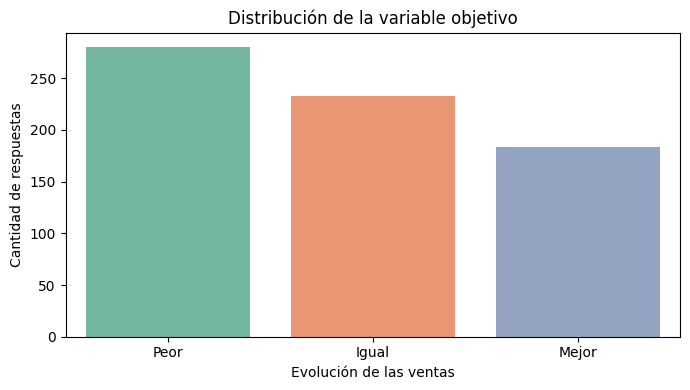

In [ ]:
# EXPLICACIÓN DE LA CELDA
# Calcula cantidades y proporciones por clase y produce un gráfico descriptivo.
# Este análisis permite detectar desbalance antes de modelar.

distribucion_clases = (
    df["Ventas"]
    .value_counts()
    .reindex(LABELS)
)

display(
    pd.DataFrame({
        "cantidad": distribucion_clases,
        "proporcion": (
            distribucion_clases
            / distribucion_clases.sum()
        )
    })
)

plt.figure(figsize=(7, 4))

sns.barplot(
    x=distribucion_clases.index,
    y=distribucion_clases.values,
    hue=distribucion_clases.index,
    palette="Set2",
    legend=False
)

plt.title("Distribución de la variable objetivo")
plt.xlabel("Evolución de las ventas")
plt.ylabel("Cantidad de respuestas")
plt.tight_layout()
plt.show()

## Longitud de los textos

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Calcula longitud en tokens y palabras, resume su distribución y muestra los extremos.

**Uso posterior.** La longitud no se utiliza como target ni se incorpora directamente al modelo; se conserva para el análisis de errores por subgrupos.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Mide longitud mediante tokens y palabras y muestra los casos extremos.
# Las columnas creadas se reutilizan posteriormente en el análisis de errores.

df["cantidad_tokens"] = (
    df["texto_original"]
    .apply(
        lambda texto: len(
            tweet_tokenizer.tokenize(
                str(texto)
            )
        )
    )
)

df["cantidad_palabras"] = (
    df["texto_original"]
    .apply(
        lambda texto: len(
            tokenizar_palabras(texto)
        )
    )
)

display(
    df[
        [
            "cantidad_tokens",
            "cantidad_palabras"
        ]
    ].describe()
)

print("Respuestas más cortas:")

display(
    df.sort_values(
        "cantidad_tokens"
    )[
        [
            "Ventas",
            "texto_original",
            "cantidad_tokens"
        ]
    ].head(10)
)

print("Respuestas más largas:")

display(
    df.sort_values(
        "cantidad_tokens",
        ascending=False
    )[
        [
            "Ventas",
            "texto_original",
            "cantidad_tokens"
        ]
    ].head(10)
)

,cantidad_tokens,cantidad_palabras
count,697.000000,697.000000
mean,7.043042,6.586801
std,6.636575,6.034265
min,1.000000,0.000000
25%,3.000000,3.000000
50%,5.000000,5.000000
75%,9.000000,9.000000
max,69.000000,60.000000


Respuestas más cortas:


,Ventas,texto_original,cantidad_tokens
687,Mejor,Temporada,1
4,Igual,Clima,1
563,Peor,Crisis,1
568,Peor,Y,1
48,Mejor,Estacional,1
62,Igual,Estabilidad,1
517,Mejor,Estacionalidad,1
472,Mejor,.,1
71,Igual,Estabilidad,1
74,Peor,Inflacion,1


Respuestas más largas:


,Ventas,texto_original,cantidad_tokens
371,Igual,"Por los impuestos de la ciudad de Tandil. Con el corte de obras públicas por parte del estado Nacional, cree que se dió el alza de impuestos a nivel local. No hay consenso para...",69
538,Igual,"Hubieron días buenos durante el mes que compensaron los días buenos, las elecciones impactaron a principio de mes pero se compensa mediante promociones. La gente aunque aumente...",48
530,Igual,"Porque ya tenemos bastantes años de experiencia, conseguimos clientes que son los mismos de siempre que vienen a comprar y, además, porque como se trata de comida la gente sigu...",46
539,Peor,"Las ventas disminuyeron por la temporada baja ya que el calor impacta en las ventas, en frio aumentaria, el mes pasado era mejor que este mes, despues del dia de las madres baj...",39
102,Igual,Permanecen iguales por qué los clientes siguen manteniendo el mismo comportamiento de compra austero. Además que es en época del año la gente cuida más el bolsillo teniendo en ...,38
586,Igual,"Permanecen igual porque la gente aunque aumente el precio vienen a comprar igual, es una zona de muchos jubilados que reciben paga de sus hijos para las compras, entonces hay c...",35
680,Igual,"Puede ser por la falta de variedad, como siempre es pollo y milanesa de pollo lo que acostumbramos a vender. Pero esperamos obviamente que las ventas sean mayores en el futuro ...",34
122,Mejor,"Hay mayor caudal de clientes por el buen clima. También ayuda la ubicación, cerca de una plaza y en esta época del año se empieza a consumir gaseosas, fiambres.",33
657,Igual,"Por la gente no compra muchas cantidades del la mercadería que antes llevaba, solo llevan lo que van a consumir en el transcurso de la semana o en el día",31
489,Igual,"Creo que el país esta parado, si bien la gente sigue ingresando, eligen productos más baratos o para compartir. Antes cada uno se pedía lo que quería",30


## Eliminación de respuestas formadas solo por puntuación

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Elimina respuestas cuyo contenido completo está formado solamente por puntuación, como `.`, `-` o `—`.

**Alcance.** No borra la puntuación dentro de respuestas válidas. El filtro se aplica antes de duplicados, grupos y particiones para impedir que estos casos entrenen o evalúen los modelos.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Identifica respuestas compuestas solo por puntuación y las elimina del corpus.
# La puntuación interna de las respuestas válidas se conserva.

# ============================================================
# ELIMINACIÓN DE RESPUESTAS FORMADAS SOLO POR PUNTUACIÓN
# ============================================================

# Conservamos el texto original y usamos una versión temporal
# únicamente para identificar respuestas sin contenido lingüístico.
texto_control = df["texto_original"].fillna("").str.strip()

# Detecta respuestas compuestas exclusivamente por signos como:
# ".", "-", "—", "...", "?", etc.
patron_solo_puntuacion = r"^[\s.,;:¿?¡!\-–—_…/\\]+$"

mask_solo_puntuacion = texto_control.str.fullmatch(
    patron_solo_puntuacion,
    na=False
)

print(
    "Respuestas formadas solamente por puntuación:",
    mask_solo_puntuacion.sum()
)

# Mostramos qué observaciones se eliminarán
display(
    df.loc[
        mask_solo_puntuacion,
        ["Ventas", "texto_original", "texto_grupo"]
    ]
)

# Eliminación
df = (
    df.loc[~mask_solo_puntuacion]
      .copy()
      .reset_index(drop=True)
)

print("Filas restantes:", len(df))

Respuestas formadas solamente por puntuación: 8


,Ventas,texto_original,texto_grupo
145,Igual,.,
187,Igual,-,
238,Mejor,—,
377,Igual,-,
378,Igual,-,
472,Mejor,.,
510,Igual,-,
609,Mejor,.,


Filas restantes: 689


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Comprueba mediante un assert que el filtro anterior fue efectivo.
# Si quedara una respuesta solo de puntuación, la ejecución se detendría.

# Verificación: no deberían quedar puntos o guiones como respuesta completa

texto_control = df["texto_original"].fillna("").str.strip()

assert not texto_control.str.fullmatch(
    patron_solo_puntuacion,
    na=False
).any()

print("Validación correcta: no quedan respuestas formadas solo por puntuación.")

Validación correcta: no quedan respuestas formadas solo por puntuación.


## Duplicados textuales

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Identifica textos que se vuelven iguales después de la normalización para grupos.

**Por qué importa.** No se eliminan automáticamente: se agrupan más adelante para evitar que respuestas equivalentes queden a ambos lados de una partición y generen leakage.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Cuenta textos normalizados repetidos y muestra todas las filas involucradas.
# La detección prepara la formación de grupos; no elimina automáticamente duplicados.

conteo_textos = (
    df["texto_grupo"]
    .value_counts()
)

textos_repetidos = conteo_textos[
    conteo_textos > 1
]

filas_duplicadas = df.loc[
    df["texto_grupo"].isin(
        textos_repetidos.index
    ),
    [
        "Ventas",
        "texto_original",
        "texto_grupo"
    ]
].sort_values(
    "texto_grupo"
)

print(
    "Textos normalizados que aparecen más de una vez:",
    len(textos_repetidos)
)

print(
    "Filas involucradas en duplicados:",
    len(filas_duplicadas)
)

display(filas_duplicadas)

Textos normalizados que aparecen más de una vez: 38
Filas involucradas en duplicados: 139


,Ventas,texto_original,texto_grupo
237,Peor,aumento de precios,aumento de precios
420,Igual,Aumento de precios,aumento de precios
330,Mejor,Clima,clima
345,Mejor,Clima,clima
170,Mejor,Clima,clima
...,...,...,...
358,Peor,Temporada,temporada
22,Mejor,Temporada,temporada
150,Mejor,temporada,temporada
221,Mejor,Temporada,temporada


## Negación y bigramas descriptivos

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Marca respuestas que contienen la negación `no` y obtiene los bigramas más frecuentes por clase.

**Interpretación.** Es un análisis descriptivo. La frecuencia de una expresión no implica causalidad ni asegura que sea útil para predecir.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Marca la negación y calcula bigramas frecuentes dentro de cada clase.
# Los bigramas se usan para exploración descriptiva, no como conclusión causal.

df["contiene_no"] = (
    df["texto_basico"]
    .str.contains(
        r"\bno\b",
        regex=True,
        na=False
    )
)

print(
    "Respuestas que contienen 'no':",
    df["contiene_no"].sum()
)


def top_bigramas(
    textos,
    cantidad=10
):
    vectorizador = CountVectorizer(
        ngram_range=(2, 2)
    )

    matriz = vectorizador.fit_transform(
        textos
    )

    frecuencias = np.asarray(
        matriz.sum(axis=0)
    ).ravel()

    resultado = pd.DataFrame({
        "bigrama": (
            vectorizador
            .get_feature_names_out()
        ),
        "frecuencia": frecuencias
    })

    return (
        resultado
        .sort_values(
            "frecuencia",
            ascending=False
        )
        .head(cantidad)
        .reset_index(drop=True)
    )


for clase in LABELS:
    print(f"\nBigramas de la clase {clase}")

    display(
        top_bigramas(
            df.loc[
                df["Ventas"] == clase,
                "texto_sin_stopwords_con_no"
            ],
            cantidad=10
        )
    )

Respuestas que contienen 'no': 130

Bigramas de la clase Peor


,bigrama,frecuencia
0,gente no,29
1,no plata,22
2,situación económica,22
3,situación país,13
4,no dinero,11
5,poder adquisitivo,9
6,económica país,9
7,economía país,6
8,no llega,6
9,llega fin,5



Bigramas de la clase Igual


,bigrama,frecuencia
0,no plata,14
1,gente no,14
2,fin mes,7
3,situación económica,4
4,no dinero,4
5,mismos clientes,3
6,precio calidad,3
7,falta dinero,3
8,no consumo,3
9,no sabe,3



Bigramas de la clase Mejor


,bigrama,frecuencia
0,día madre,7
1,temporada verano,5
2,dia madre,3
3,mas gente,3
4,redes sociales,3
5,calidad productos,3
6,temporada alta,3
7,mes pasado,3
8,cambio temporada,3
9,no sabe,2


## Normalización del nombre del comercio

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Normaliza el nombre del comercio y transforma valores administrativos o vacíos en faltantes.

**Uso.** Esta variable se utiliza para formar grupos de observaciones relacionadas, no como feature del clasificador.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Normaliza nombres comerciales y convierte respuestas administrativas en faltantes.
# El nombre normalizado se emplea únicamente para relacionar registros.

def normalizar_nombre(valor):
    if pd.isna(valor):
        return pd.NA

    valor = normalizar_para_grupos(
        valor
    )

    valores_invalidos = {
        "",
        "no",
        "no tiene",
        "sin nombre",
        "no tiene nombre",
        "ninguno",
        "ninguna",
        "n a",
        "na"
    }

    if valor in valores_invalidos:
        return pd.NA

    return valor


df["nombre_normalizado"] = (
    df[COL_NOMBRE]
    .apply(normalizar_nombre)
)

## Extracción de coordenadas

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Extrae latitud y longitud, las convierte a números y descarta coordenadas fuera de los rangos geográficos válidos.

Las coordenadas ayudan a reconocer registros posiblemente pertenecientes al mismo comercio y no se usan como información predictiva.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Extrae coordenadas con regex, convierte tipos y valida rangos geográficos.
# Las coordenadas inválidas quedan como NaN y no fuerzan agrupaciones.

coordenadas = (
    df[COL_COORDENADAS]
    .astype("string")
    .str.extract(
        r"(-?\d+(?:\.\d+)?)\s*,\s*"
        r"(-?\d+(?:\.\d+)?)"
    )
)

df["latitud"] = pd.to_numeric(
    coordenadas[0],
    errors="coerce"
)

df["longitud"] = pd.to_numeric(
    coordenadas[1],
    errors="coerce"
)

coordenada_valida = (
    df["latitud"].between(-90, 90)
    & df["longitud"].between(-180, 180)
)

df.loc[
    ~coordenada_valida,
    ["latitud", "longitud"]
] = np.nan

## Funciones para agrupar observaciones relacionadas

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Define una estructura Union-Find para unir observaciones relacionadas y la fórmula de Haversine para calcular distancia geográfica.

**Idea.** Si A está unida con B y B con C, Union-Find mantiene a las tres dentro del mismo grupo, aunque no todas las relaciones se hayan declarado de forma directa.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Implementa Union-Find y la distancia Haversine en metros.
# Ambas utilidades sirven para construir grupos independientes de observaciones.

class UnionFind:
    def __init__(self, cantidad):
        self.parent = list(
            range(cantidad)
        )
        self.rank = [0] * cantidad

    def find(self, elemento):
        if (
            self.parent[elemento]
            != elemento
        ):
            self.parent[elemento] = (
                self.find(
                    self.parent[elemento]
                )
            )

        return self.parent[elemento]

    def union(self, primero, segundo):
        raiz_1 = self.find(primero)
        raiz_2 = self.find(segundo)

        if raiz_1 == raiz_2:
            return

        if (
            self.rank[raiz_1]
            < self.rank[raiz_2]
        ):
            self.parent[raiz_1] = raiz_2

        elif (
            self.rank[raiz_1]
            > self.rank[raiz_2]
        ):
            self.parent[raiz_2] = raiz_1

        else:
            self.parent[raiz_2] = raiz_1
            self.rank[raiz_1] += 1


def distancia_metros(
    latitud_1,
    longitud_1,
    latitud_2,
    longitud_2
):
    radio_tierra = 6_371_000

    latitud_1 = np.radians(
        latitud_1
    )
    longitud_1 = np.radians(
        longitud_1
    )
    latitud_2 = np.radians(
        latitud_2
    )
    longitud_2 = np.radians(
        longitud_2
    )

    diferencia_latitud = (
        latitud_2 - latitud_1
    )
    diferencia_longitud = (
        longitud_2 - longitud_1
    )

    a = (
        np.sin(
            diferencia_latitud / 2
        ) ** 2
        + np.cos(latitud_1)
        * np.cos(latitud_2)
        * np.sin(
            diferencia_longitud / 2
        ) ** 2
    )

    return (
        2
        * radio_tierra
        * np.arcsin(np.sqrt(a))
    )

## Formación de grupos

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Une textos duplicados y registros con el mismo comercio a menos de 50 metros. Luego asigna un identificador de grupo a cada observación.

**Objetivo.** Cada grupo debe permanecer completo en train, validación o test para reducir el riesgo de leakage por registros relacionados.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Une duplicados textuales y comercios coincidentes dentro de un radio de 50 metros.
# Finalmente asigna un identificador entero de grupo a cada fila.

union_find = UnionFind(len(df))

# Une textos normalizados idénticos.
for indices in (
    df.groupby("texto_grupo")
    .groups
    .values()
):
    indices = list(indices)

    for indice in indices[1:]:
        union_find.union(
            indices[0],
            indice
        )


# Une respuestas del mismo comercio.
pares_mismo_comercio = []

casos_con_comercio = df.dropna(
    subset=[
        "nombre_normalizado",
        "latitud",
        "longitud"
    ]
)

for nombre, grupo_comercio in (
    casos_con_comercio
    .groupby("nombre_normalizado")
):
    if len(grupo_comercio) < 2:
        continue

    for indice_1, indice_2 in combinations(
        grupo_comercio.index,
        2
    ):
        distancia = distancia_metros(
            df.loc[indice_1, "latitud"],
            df.loc[indice_1, "longitud"],
            df.loc[indice_2, "latitud"],
            df.loc[indice_2, "longitud"]
        )

        if distancia <= 50:
            union_find.union(
                indice_1,
                indice_2
            )

            pares_mismo_comercio.append({
                "indice_1": indice_1,
                "indice_2": indice_2,
                "nombre": nombre,
                "distancia_metros": round(
                    distancia,
                    2
                )
            })


raices = [
    union_find.find(indice)
    for indice in range(len(df))
]

df["grupo"] = pd.factorize(
    raices
)[0]

print("Observaciones:", len(df))
print("Grupos independientes:", df["grupo"].nunique())
print("Pares del mismo comercio:", len(pares_mismo_comercio))

display(
    pd.DataFrame(
        pares_mismo_comercio
    )
)

Observaciones: 689
Grupos independientes: 587
Pares del mismo comercio: 1


,indice_1,indice_2,nombre,distancia_metros
0,641,680,carniceria alejandro,14.24


## Grupos con etiquetas diferentes

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Revisa si un mismo grupo contiene más de una etiqueta de ventas.

Un conflicto no implica necesariamente un error: un comercio o una explicación repetida puede aparecer con etiquetas diferentes. Lo importante es que el grupo no se divida entre particiones.


No se eliminan. Solamente se mantienen en la misma partición.

<!-- EXPLICACION_AGREGADA -->
Los conflictos se conservan porque eliminarlos podría borrar variación real o introducir un criterio basado en la etiqueta. La agrupación evita que produzcan contaminación entre particiones.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Detecta grupos que contienen más de una etiqueta y los muestra para auditoría.
# Los conflictos se conservan, pero nunca se separan entre particiones.

grupos_con_conflicto = (
    df.groupby("grupo")["Ventas"]
    .nunique()
    .loc[lambda serie: serie > 1]
)

print(
    "Grupos con más de una etiqueta:",
    len(grupos_con_conflicto)
)

if len(grupos_con_conflicto) > 0:
    display(
        df.loc[
            df["grupo"].isin(
                grupos_con_conflicto.index
            ),
            [
                "grupo",
                "Ventas",
                "texto_original"
            ]
        ].sort_values(
            "grupo"
        )
    )

Grupos con más de una etiqueta: 25


,grupo,Ventas,texto_original
4,4,Igual,Clima
25,4,Igual,Clima
170,4,Mejor,Clima
345,4,Mejor,Clima
330,4,Mejor,Clima
...,...,...,...
581,424,Igual,Por estacionalidad
488,424,Peor,Por estacionalidad
569,480,Igual,La gente no tiene dinero
554,480,Peor,La gente no tiene dinero


## Separación entre desarrollo y test

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Reserva aproximadamente un sexto del corpus como test mediante `StratifiedGroupKFold` y elige, entre los seis folds candidatos, el que mejor conserva tamaño y proporciones de clase.

**Garantía.** El `assert` verifica que ningún grupo aparezca simultáneamente en development y test. El test queda reservado para la evaluación posterior.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Construye un test agrupado cercano a un sexto del corpus y balanceado por clase.
# Selecciona el fold candidato más parecido al total sin mezclar grupos.

y_completo = (
    df["Ventas"]
    .reset_index(drop=True)
)

grupos_completos = (
    df["grupo"]
    .reset_index(drop=True)
)

indices_completos = np.arange(
    len(df)
)

proporcion_global = (
    y_completo
    .value_counts(normalize=True)
    .reindex(
        LABELS,
        fill_value=0
    )
)

partidor_test = StratifiedGroupKFold(
    n_splits=6,
    shuffle=True,
    random_state=SEED
)

particiones_candidatas = list(
    partidor_test.split(
        indices_completos,
        y_completo,
        groups=grupos_completos
    )
)


def puntaje_particion(
    indices_test
):
    proporcion_test = (
        y_completo
        .iloc[indices_test]
        .value_counts(normalize=True)
        .reindex(
            LABELS,
            fill_value=0
        )
    )

    diferencia_clases = (
        proporcion_test
        - proporcion_global
    ).abs().sum()

    diferencia_tamano = abs(
        len(indices_test)
        / len(df)
        - 1 / 6
    )

    return (
        diferencia_clases
        + diferencia_tamano
    )


puntajes = [
    puntaje_particion(
        indices_test
    )
    for _, indices_test
    in particiones_candidatas
]

mejor_fold_test = int(
    np.argmin(puntajes)
)

indices_dev, indices_test = (
    particiones_candidatas[
        mejor_fold_test
    ]
)

df_dev = (
    df.iloc[indices_dev]
    .copy()
    .reset_index(drop=True)
)

df_test = (
    df.iloc[indices_test]
    .copy()
    .reset_index(drop=True)
)

assert set(
    df_dev["grupo"]
).isdisjoint(
    set(df_test["grupo"])
)

print("Desarrollo:", len(df_dev))
print("Test:", len(df_test))

print("\nDistribución desarrollo:")
display(
    df_dev["Ventas"]
    .value_counts(normalize=True)
    .reindex(LABELS)
)

print("\nDistribución test:")
display(
    df_test["Ventas"]
    .value_counts(normalize=True)
    .reindex(LABELS)
)

Desarrollo: 585
Test: 104

Distribución desarrollo:


,proportion
Ventas,
Peor,0.410256
Igual,0.328205
Mejor,0.261538



Distribución test:


,proportion
Ventas,
Peor,0.384615
Igual,0.346154
Mejor,0.269231


## Folds de validación cruzada

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Construye cinco folds estratificados y agrupados dentro de development.

**Selección.** Los experimentos usan exactamente estos mismos folds y se comparan por el macro-F1 medio. La semilla es única y fija para reproducibilidad; no se repite la validación con cinco semillas.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Crea cinco folds estratificados y agrupados dentro de development.
# Los assert verifican que train y validación nunca compartan grupos.

y_dev = df_dev["Ventas"]
grupos_dev = df_dev["grupo"]

partidor_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

CV_SPLITS = list(
    partidor_cv.split(
        np.arange(len(df_dev)),
        y_dev,
        groups=grupos_dev
    )
)

for numero, (
    indices_train,
    indices_validacion
) in enumerate(
    CV_SPLITS,
    start=1
):
    grupos_train = set(
        grupos_dev.iloc[
            indices_train
        ]
    )

    grupos_validacion = set(
        grupos_dev.iloc[
            indices_validacion
        ]
    )

    assert grupos_train.isdisjoint(
        grupos_validacion
    )

    print(
        f"Fold {numero}: "
        f"train={len(indices_train)}, "
        f"validación={len(indices_validacion)}"
    )

Fold 1: train=483, validación=102
Fold 2: train=475, validación=110
Fold 3: train=467, validación=118
Fold 4: train=447, validación=138
Fold 5: train=468, validación=117


## Funciones de evaluación

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Define funciones que resumen los resultados de `cross_validate` y `GridSearchCV` con una estructura común.

`macro_f1_cv` es el promedio entre folds y `desvio_macro_f1` cuantifica la variación entre esos folds. No debe confundirse con el desvío bootstrap calculado sobre test.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Unifica el formato de resultados de cross_validate y GridSearchCV.
# Devuelve promedio y desvío de macro-F1 calculados entre folds.

def resumir_cross_validate(
    nombre,
    resultados
):
    return {
        "modelo": nombre,
        "macro_f1_cv": (
            resultados[
                "test_macro_f1"
            ].mean()
        ),
        "desvio_macro_f1": (
            resultados[
                "test_macro_f1"
            ].std()
        ),
        "accuracy_cv": (
            resultados[
                "test_accuracy"
            ].mean()
        )
    }


def resumir_grid(
    nombre,
    grid
):
    indice = grid.best_index_

    return {
        "modelo": nombre,
        "macro_f1_cv": (
            grid.cv_results_[
                "mean_test_score"
            ][indice]
        ),
        "desvio_macro_f1": (
            grid.cv_results_[
                "std_test_score"
            ][indice]
        ),
        "accuracy_cv": np.nan
    }

# Baselines

## Baseline de clase mayoritaria

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Implementa una baseline que aprende la clase mayoritaria del conjunto de entrenamiento y la predice para todos los casos.

**Función metodológica.** Establece un piso mínimo: un modelo de NLP debería superarla de manera clara.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Define un estimador compatible con scikit-learn que siempre predice la clase mayoritaria.
# fit aprende la clase; predict repite esa clase para todas las observaciones.

class BaselineMayoritario(
    BaseEstimator,
    ClassifierMixin
):
    def fit(self, X, y):
        y = pd.Series(y)

        self.clase_mayoritaria_ = (
            y.value_counts().idxmax()
        )

        self.classes_ = np.sort(
            y.unique()
        )

        return self

    def predict(self, X):
        return np.repeat(
            self.clase_mayoritaria_,
            len(X)
        )

## Baseline de reglas

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Implementa una baseline basada en patrones direccionales. Si encuentra exactamente una dirección, devuelve esa clase; ante ausencia o ambigüedad, usa la clase mayoritaria aprendida.

Esta baseline permite medir cuánto se obtiene con reglas simples antes de justificar modelos más complejos.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Define patrones direccionales y una baseline de reglas compatible con scikit-learn.
# Ante múltiples coincidencias o ninguna, utiliza la clase mayoritaria del train.

PATRONES_REGLAS = {
    "Mejor": re.compile(
        r"\b(?:"
        r"mejor\w*|aument\w*|increment\w*|"
        r"sub(?:e|en|ió|io|ieron|ida|iendo)|"
        r"crec\w*"
        r")\b",
        flags=re.IGNORECASE
    ),
    "Peor": re.compile(
        r"\b(?:"
        r"peor\w*|baj\w*|disminu\w*|"
        r"ca[ií]\w*|cay\w*|redu\w*"
        r")\b",
        flags=re.IGNORECASE
    ),
    "Igual": re.compile(
        r"\b(?:"
        r"igual\w*|manten\w*|establ\w*|"
        r"sin cambios?|no vari\w*"
        r")\b",
        flags=re.IGNORECASE
    )
}


class BaselineReglas(
    BaseEstimator,
    ClassifierMixin
):
    def fit(self, X, y):
        y = pd.Series(y)

        self.clase_mayoritaria_ = (
            y.value_counts().idxmax()
        )

        self.classes_ = np.sort(
            y.unique()
        )

        return self

    def _predecir_texto(self, texto):
        texto = normalizar_basico(
            texto
        )

        coincidencias = [
            clase
            for clase, patron
            in PATRONES_REGLAS.items()
            if patron.search(texto)
        ]

        if len(coincidencias) == 1:
            return coincidencias[0]

        return self.clase_mayoritaria_

    def predict(self, X):
        return np.array([
            self._predecir_texto(texto)
            for texto in X
        ])

## Evaluación de baselines

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Evalúa las dos baselines con los mismos cinco folds de development y calcula macro-F1 y accuracy.

El conjunto de test todavía no interviene en esta comparación.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Evalúa las dos baselines usando exactamente los mismos folds de development.
# Guarda macro-F1 medio, su desvío y accuracy media.

X_dev_original = (
    df_dev["texto_original"]
)

baseline_mayoritario = (
    BaselineMayoritario()
)

baseline_reglas = (
    BaselineReglas()
)

cv_mayoritario = cross_validate(
    baseline_mayoritario,
    X_dev_original,
    y_dev,
    cv=CV_SPLITS,
    scoring={
        "macro_f1": "f1_macro",
        "accuracy": "accuracy"
    },
    n_jobs=1
)

cv_reglas = cross_validate(
    baseline_reglas,
    X_dev_original,
    y_dev,
    cv=CV_SPLITS,
    scoring={
        "macro_f1": "f1_macro",
        "accuracy": "accuracy"
    },
    n_jobs=1
)

resultado_mayoritario = (
    resumir_cross_validate(
        "Baseline mayoritaria",
        cv_mayoritario
    )
)

resultado_reglas = (
    resumir_cross_validate(
        "Baseline reglas",
        cv_reglas
    )
)

display(
    pd.DataFrame([
        resultado_mayoritario,
        resultado_reglas
    ])
)

,modelo,macro_f1_cv,desvio_macro_f1,accuracy_cv
0,Baseline mayoritaria,0.191019,0.027088,0.406142
1,Baseline reglas,0.293986,0.058640,0.433650


# Modelo Palabras

## Configuraciones de BoW y TF-IDF de palabras

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Declara las representaciones de palabras que se compararán: BoW, TF-IDF, n-gramas, stopwords, mayúsculas, acentos, stemming, lematización y límites de vocabulario.

Cada configuración especifica la columna textual correspondiente y el vectorizador. La vectorización se ajusta dentro del pipeline y dentro de cada fold.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Declara las configuraciones BoW y TF-IDF que se compararán.
# Cada configuración registra su columna de entrada y su vectorizador.

STOPWORDS_COMPLETAS = sorted(
    STOPWORDS_ES
)

STOPWORDS_CON_NO_CONSERVADO = sorted(
    STOPWORDS_ES - {"no"}
)

configuraciones_palabras = [
    {
        "nombre": "BoW unigramas",
        "columna": "texto_original",
        "vectorizador": CountVectorizer(
            ngram_range=(1, 1)
        )
    },
    {
        "nombre": "BoW unigramas+bigrams",
        "columna": "texto_original",
        "vectorizador": CountVectorizer(
            ngram_range=(1, 2)
        )
    },
    {
        "nombre": "BoW binario unigramas+bigrams",
        "columna": "texto_original",
        "vectorizador": CountVectorizer(
            ngram_range=(1, 2),
            binary=True
        )
    },
    {
        "nombre": "TF-IDF unigramas",
        "columna": "texto_original",
        "vectorizador": TfidfVectorizer(
            ngram_range=(1, 1)
        )
    },
    {
        "nombre": "TF-IDF unigramas+bigrams",
        "columna": "texto_original",
        "vectorizador": TfidfVectorizer(
            ngram_range=(1, 2)
        )
    },
    {
        "nombre": "TF-IDF hasta trigramas",
        "columna": "texto_original",
        "vectorizador": TfidfVectorizer(
            ngram_range=(1, 3)
        )
    },
    {
        "nombre": "TF-IDF sin stopwords conservando no",
        "columna": "texto_original",
        "vectorizador": TfidfVectorizer(
            ngram_range=(1, 2),
            stop_words=(
                STOPWORDS_CON_NO_CONSERVADO
            )
        )
    },
    {
        "nombre": "TF-IDF sin stopwords eliminando no",
        "columna": "texto_original",
        "vectorizador": TfidfVectorizer(
            ngram_range=(1, 2),
            stop_words=STOPWORDS_COMPLETAS
        )
    },
    {
        "nombre": "TF-IDF TweetTokenizer",
        "columna": "texto_original",
        "vectorizador": TfidfVectorizer(
            tokenizer=tokenizar_tweet,
            token_pattern=None,
            ngram_range=(1, 2)
        )
    },
    {
        "nombre": "TF-IDF sin minúsculas",
        "columna": "texto_original",
        "vectorizador": TfidfVectorizer(
            lowercase=False,
            ngram_range=(1, 2)
        )
    },
    {
        "nombre": "TF-IDF sin acentos",
        "columna": "texto_sin_acentos",
        "vectorizador": TfidfVectorizer(
            lowercase=False,
            ngram_range=(1, 2)
        )
    },
    {
        "nombre": "TF-IDF stemming",
        "columna": "texto_stemming",
        "vectorizador": TfidfVectorizer(
            lowercase=False,
            ngram_range=(1, 2)
        )
    },
    {
        "nombre": "TF-IDF lematización",
        "columna": "texto_lematizado",
        "vectorizador": TfidfVectorizer(
            lowercase=False,
            ngram_range=(1, 2)
        )
    },
    {
        "nombre": "TF-IDF máximo 500 features",
        "columna": "texto_original",
        "vectorizador": TfidfVectorizer(
            ngram_range=(1, 2),
            max_features=500
        )
    },
    {
        "nombre": "TF-IDF máximo 1000 features",
        "columna": "texto_original",
        "vectorizador": TfidfVectorizer(
            ngram_range=(1, 2),
            max_features=1000
        )
    },
    {
        "nombre": "TF-IDF min_df 2 max_df 0.95",
        "columna": "texto_original",
        "vectorizador": TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95
        )
    }
]

Definimos también los clasificadores de palabras.

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Define LogisticRegression y LinearSVC y la grilla de hiperparámetros `C` y `class_weight`.

`C` controla la regularización y `class_weight='balanced'` compensa automáticamente diferencias de frecuencia entre clases.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Define los clasificadores lineales y la grilla común de hiperparámetros.
# La búsqueda considera regularización C y balance automático de clases.

clasificadores_palabras = {
    "LogisticRegression": (
        LogisticRegression(
            max_iter=3000,
            random_state=SEED
        )
    ),
    "LinearSVC": (
        LinearSVC(
            random_state=SEED
        )
    )
}

PARAMETROS_CLASIFICADOR = {
    "clasificador__C": [
        0.5,
        1.0,
        2.0
    ],
    "clasificador__class_weight": [
        None,
        "balanced"
    ]
}

## Ejecución de experimentos de palabras

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Combina cada representación con cada clasificador, ejecuta `GridSearchCV` sobre los folds prefijados y guarda resultados, búsquedas y metadatos.

**Prevención de leakage.** El vectorizador se ajusta dentro del pipeline utilizando solamente el train de cada fold.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Ejecuta cada combinación de representación y clasificador mediante GridSearchCV.
# Guarda el objeto ajustado y metadatos para evaluación e interpretación posteriores.

resultados_palabras = []
busquedas_palabras = {}
metadatos_palabras = {}

for configuracion in configuraciones_palabras:
    nombre_configuracion = (
        configuracion["nombre"]
    )
    columna = configuracion["columna"]
    vectorizador = (
        configuracion["vectorizador"]
    )

    X_configuracion = (
        df_dev[columna]
    )

    for nombre_clasificador, clasificador in (
        clasificadores_palabras.items()
    ):
        nombre_experimento = (
            f"{nombre_configuracion} + "
            f"{nombre_clasificador}"
        )

        print(
            "\nEjecutando:",
            nombre_experimento
        )

        pipeline = Pipeline([
            (
                "vectorizador",
                clone(vectorizador)
            ),
            (
                "clasificador",
                clone(clasificador)
            )
        ])

        grid = GridSearchCV(
            estimator=pipeline,
            param_grid=(
                PARAMETROS_CLASIFICADOR
            ),
            scoring="f1_macro",
            cv=CV_SPLITS,
            refit=True,
            n_jobs=-1,
            verbose=0,
            return_train_score=False
        )

        grid.fit(
            X_configuracion,
            y_dev
        )

        fila_resultado = resumir_grid(
            nombre_experimento,
            grid
        )

        fila_resultado["columna_texto"] = (
            columna
        )

        resultados_palabras.append(
            fila_resultado
        )

        busquedas_palabras[
            nombre_experimento
        ] = grid

        metadatos_palabras[
            nombre_experimento
        ] = {
            "columna": columna,
            "configuracion": (
                nombre_configuracion
            ),
            "clasificador": (
                nombre_clasificador
            )
        }


Ejecutando: BoW unigramas + LogisticRegression

Ejecutando: BoW unigramas + LinearSVC

Ejecutando: BoW unigramas+bigrams + LogisticRegression

Ejecutando: BoW unigramas+bigrams + LinearSVC

Ejecutando: BoW binario unigramas+bigrams + LogisticRegression

Ejecutando: BoW binario unigramas+bigrams + LinearSVC

Ejecutando: TF-IDF unigramas + LogisticRegression

Ejecutando: TF-IDF unigramas + LinearSVC

Ejecutando: TF-IDF unigramas+bigrams + LogisticRegression

Ejecutando: TF-IDF unigramas+bigrams + LinearSVC

Ejecutando: TF-IDF hasta trigramas + LogisticRegression

Ejecutando: TF-IDF hasta trigramas + LinearSVC

Ejecutando: TF-IDF sin stopwords conservando no + LogisticRegression

Ejecutando: TF-IDF sin stopwords conservando no + LinearSVC

Ejecutando: TF-IDF sin stopwords eliminando no + LogisticRegression

Ejecutando: TF-IDF sin stopwords eliminando no + LinearSVC

Ejecutando: TF-IDF TweetTokenizer + LogisticRegression

Ejecutando: TF-IDF TweetTokenizer + LinearSVC

Ejecutando: TF-IDF s

## Resultados de palabras

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Ordena los experimentos clásicos por macro-F1 medio, identifica el mejor modelo de palabras y muestra sus hiperparámetros.

La decisión se basa en development; no se consulta test en esta etapa.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Ordena los modelos de palabras por macro-F1 medio y conserva el mejor.
# También muestra los hiperparámetros seleccionados dentro de development.

tabla_palabras = (
    pd.DataFrame(
        resultados_palabras
    )
    .sort_values(
        "macro_f1_cv",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    tabla_palabras.style.format({
        "macro_f1_cv": "{:.3f}",
        "desvio_macro_f1": "{:.3f}",
        "accuracy_cv": "{:.3f}" # en este caso no calculamos accuracy, pero podriamos haberlo incorporado como scoring del CV
    })
)

MEJOR_MODELO_PALABRAS = (
    tabla_palabras.loc[
        0,
        "modelo"
    ]
)

print(
    "Mejor modelo de palabras:",
    MEJOR_MODELO_PALABRAS
)

print("Parámetros:")
display(
    busquedas_palabras[
        MEJOR_MODELO_PALABRAS
    ].best_params_
)

,modelo,macro_f1_cv,desvio_macro_f1,accuracy_cv,columna_texto
0,TF-IDF stemming + LogisticRegression,0.587,0.033,nan,texto_stemming
1,TF-IDF stemming + LinearSVC,0.582,0.036,nan,texto_stemming
2,TF-IDF sin acentos + LogisticRegression,0.574,0.031,nan,texto_sin_acentos
3,TF-IDF lematización + LinearSVC,0.566,0.019,nan,texto_lematizado
4,TF-IDF sin acentos + LinearSVC,0.564,0.031,nan,texto_sin_acentos
5,TF-IDF lematización + LogisticRegression,0.563,0.036,nan,texto_lematizado
6,TF-IDF unigramas+bigrams + LogisticRegression,0.563,0.038,nan,texto_original
7,TF-IDF sin minúsculas + LogisticRegression,0.559,0.032,nan,texto_original
8,TF-IDF TweetTokenizer + LogisticRegression,0.558,0.025,nan,texto_original
9,TF-IDF hasta trigramas + LogisticRegression,0.558,0.023,nan,texto_original


Mejor modelo de palabras: TF-IDF stemming + LogisticRegression
Parámetros:


{'clasificador__C': 2.0, 'clasificador__class_weight': 'balanced'}

## Comparaciones de hipótesis textuales

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Extrae un subconjunto de experimentos para comparar hipótesis de preparación textual.

La tabla permite observar si stopwords, negación, bigramas, stemming o lematización cambian el rendimiento y la estabilidad.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Filtra experimentos comparables para estudiar decisiones de preparación textual.
# Se muestran conjuntamente desempeño medio y variación entre folds.

experimentos_interes = [
    "TF-IDF unigramas",
    "TF-IDF unigramas+bigrams",
    "TF-IDF sin stopwords conservando no",
    "TF-IDF sin stopwords eliminando no",
    "TF-IDF stemming",
    "TF-IDF lematización"
]

comparacion_textual = (
    tabla_palabras.loc[
        tabla_palabras[
            "modelo"
        ].str.startswith(
            tuple(experimentos_interes)
        )
    ]
    .copy()
)

display(
    comparacion_textual[
        [
            "modelo",
            "macro_f1_cv",
            "desvio_macro_f1"
        ]
    ].sort_values(
        "macro_f1_cv",
        ascending=False
    )
)

,modelo,macro_f1_cv,desvio_macro_f1
0,TF-IDF stemming + LogisticRegression,0.587263,0.032861
1,TF-IDF stemming + LinearSVC,0.582318,0.035931
3,TF-IDF lematización + LinearSVC,0.566061,0.019494
5,TF-IDF lematización + LogisticRegression,0.563432,0.036413
6,TF-IDF unigramas+bigrams + LogisticRegression,0.562506,0.038267
10,TF-IDF sin stopwords conservando no + LogisticRegression,0.554678,0.057311
13,TF-IDF unigramas+bigrams + LinearSVC,0.552352,0.029119
14,TF-IDF unigramas + LinearSVC,0.551247,0.027209
15,TF-IDF unigramas + LogisticRegression,0.549702,0.026709
21,TF-IDF sin stopwords conservando no + LinearSVC,0.546424,0.050074


# Modelo Caracteres

## Modelo TF-IDF de caracteres

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Evalúa TF-IDF de n-gramas de caracteres con LogisticRegression y LinearSVC.

Los caracteres pueden capturar errores ortográficos, variantes morfológicas y diferencias de acentuación sin depender de una tokenización perfecta.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Busca la mejor combinación de TF-IDF de caracteres y clasificador lineal.
# La representación se ajusta dentro de cada fold para evitar leakage.

pipeline_caracteres = Pipeline([
    (
        "vectorizador",
        TfidfVectorizer(
            lowercase=True,
            sublinear_tf=True
        )
    ),
    (
        "clasificador",
        LogisticRegression(
            max_iter=3000,
            random_state=SEED
        )
    )
])

parametros_caracteres_comunes = {
    "vectorizador__analyzer": [
        "char",
        "char_wb"
    ],
    "vectorizador__ngram_range": [
        (3, 5),
        (3, 6)
    ],
    "vectorizador__min_df": [
        1,
        2
    ],
    "vectorizador__max_features": [
        None,
        5000
    ]
}

parametros_caracteres = [
    {
        **parametros_caracteres_comunes,
        "clasificador": [
            LogisticRegression(
                max_iter=3000,
                random_state=SEED
            )
        ],
        "clasificador__C": [
            0.5,
            1.0,
            2.0
        ],
        "clasificador__class_weight": [
            None,
            "balanced"
        ]
    },
    {
        **parametros_caracteres_comunes,
        "clasificador": [
            LinearSVC(
                random_state=SEED
            )
        ],
        "clasificador__C": [
            0.5,
            1.0,
            2.0
        ],
        "clasificador__class_weight": [
            None,
            "balanced"
        ]
    }
]

grid_caracteres = GridSearchCV(
    estimator=pipeline_caracteres,
    param_grid=parametros_caracteres,
    scoring="f1_macro",
    cv=CV_SPLITS,
    refit=True,
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

grid_caracteres.fit(
    df_dev["texto_original"],
    y_dev
)

resultado_caracteres = resumir_grid(
    "TF-IDF caracteres",
    grid_caracteres
)

print(
    "Macro-F1 CV:",
    grid_caracteres.best_score_
)

display(
    grid_caracteres.best_params_
)

Fitting 5 folds for each of 192 candidates, totalling 960 fits
Macro-F1 CV: 0.5911569674449585


{'clasificador': LogisticRegression(max_iter=3000, random_state=42),
 'clasificador__C': 1.0,
 'clasificador__class_weight': 'balanced',
 'vectorizador__analyzer': 'char_wb',
 'vectorizador__max_features': 5000,
 'vectorizador__min_df': 1,
 'vectorizador__ngram_range': (3, 6)}

# Modelo Embeddings Estáticos

## Descarga de vectores FastText en español

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Declara la fuente oficial y descarga los vectores FastText preentrenados en español si todavía no existen en la sesión.

El archivo es grande; por eso la celda siguiente conserva únicamente las palabras presentes en el corpus.


Se utiliza el archivo oficial de vectores FastText Common Crawl en español.

<!-- EXPLICACION_AGREGADA -->
FastText aporta embeddings estáticos de palabras. Estos vectores fueron entrenados externamente y aquí se utilizan como representación, no como etiquetas ni predicciones.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Descarga los embeddings FastText oficiales en español si no están en /content.
# La opción -c permite continuar una descarga interrumpida.

FASTTEXT_URL = (
    "https://dl.fbaipublicfiles.com/"
    "fasttext/vectors-crawl/"
    "cc.es.300.vec.gz"
)

FASTTEXT_PATH = Path(
    "/content/cc.es.300.vec.gz"
)

if not FASTTEXT_PATH.exists():
    !wget -c "$FASTTEXT_URL" -O "$FASTTEXT_PATH"
else:
    print("El archivo FastText ya existe.")

El archivo FastText ya existe.


## Extracción de vectores necesarios

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Construye el vocabulario real del corpus y filtra el archivo preentrenado para conservar únicamente vectores necesarios.

Esto reduce el uso de memoria sin alterar los vectores de las palabras que sí aparecen en las respuestas.


Para no cargar millones de palabras en memoria, se conservan solamente los vectores de las palabras presentes en el corpus.

<!-- EXPLICACION_AGREGADA -->
La cobertura informa qué proporción del vocabulario dispone de embedding. Las palabras sin vector se omiten al construir la representación del documento.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Construye el vocabulario único del corpus después de la normalización básica.
# Se usa para evitar cargar embeddings de palabras que nunca aparecen.

vocabulario_corpus = set()

for texto in df["texto_basico"]:
    vocabulario_corpus.update(
        tokenizar_palabras(texto)
    )

print(
    "Vocabulario del corpus:",
    len(vocabulario_corpus)
)

Vocabulario del corpus: 923


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Recorre el archivo comprimido y conserva solamente los vectores del vocabulario.
# Al final informa cobertura para controlar palabras fuera de vocabulario.

vectores_fasttext = {}

with gzip.open(
    FASTTEXT_PATH,
    mode="rt",
    encoding="utf-8",
    errors="ignore"
) as archivo:
    encabezado = archivo.readline()
    cantidad_vectores, dimension = map(
        int,
        encabezado.strip().split()
    )

    for linea in tqdm(
        archivo,
        total=cantidad_vectores,
        desc="Leyendo FastText"
    ):
        partes = linea.rstrip().split()

        if len(partes) != dimension + 1:
            continue

        palabra = partes[0]

        if palabra not in vocabulario_corpus:
            continue

        vector = np.asarray(
            partes[1:],
            dtype=np.float32
        )

        vectores_fasttext[
            palabra
        ] = vector

print(
    "Palabras con vector FastText:",
    len(vectores_fasttext)
)

print(
    "Cobertura del vocabulario:",
    round(
        len(vectores_fasttext)
        / len(vocabulario_corpus),
        3
    )
)

Leyendo FastText:   0%|          | 0/2000000 [00:00<?, ?it/s]

Palabras con vector FastText: 908
Cobertura del vocabulario: 0.984


## Transformador de documentos FastText

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Define un transformador compatible con scikit-learn que promedia embeddings FastText y permite ponderarlos con TF-IDF y normalizarlos.

**Limitación.** El promedio resume las palabras, pero pierde gran parte del orden y del contexto de la oración.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Convierte cada documento en el promedio de sus vectores FastText.
# Permite ponderación TF-IDF y normalización L2 dentro de un pipeline reproducible.

class FastTextDocumentVectorizer(
    BaseEstimator,
    TransformerMixin
):
    def __init__(
        self,
        vectores,
        ponderar_tfidf=False,
        normalizar_l2=False
    ):
        self.vectores = vectores
        self.ponderar_tfidf = (
            ponderar_tfidf
        )
        self.normalizar_l2 = (
            normalizar_l2
        )

    def fit(self, X, y=None):
        if len(self.vectores) == 0:
            raise ValueError(
                "No se cargaron vectores FastText."
            )

        self.dimension_ = len(
            next(
                iter(
                    self.vectores.values()
                )
            )
        )

        if self.ponderar_tfidf:
            self.tfidf_ = TfidfVectorizer(
                tokenizer=tokenizar_palabras,
                token_pattern=None,
                lowercase=False
            )

            self.tfidf_.fit(X)

            features = (
                self.tfidf_
                .get_feature_names_out()
            )

            self.idf_ = dict(
                zip(
                    features,
                    self.tfidf_.idf_
                )
            )

            self.idf_default_ = max(
                self.tfidf_.idf_
            )

        return self

    def _vector_documento(self, texto):
        tokens = tokenizar_palabras(
            texto
        )

        vectores = []
        pesos = []

        for token in tokens:
            if token not in self.vectores:
                continue

            vectores.append(
                self.vectores[token]
            )

            if self.ponderar_tfidf:
                pesos.append(
                    self.idf_.get(
                        token,
                        self.idf_default_
                    )
                )
            else:
                pesos.append(1.0)

        if len(vectores) == 0:
            return np.zeros(
                self.dimension_,
                dtype=np.float32
            )

        vector_documento = np.average(
            np.vstack(vectores),
            axis=0,
            weights=np.asarray(pesos)
        )

        if self.normalizar_l2:
            norma = np.linalg.norm(
                vector_documento
            )

            if norma > 0:
                vector_documento = (
                    vector_documento
                    / norma
                )

        return vector_documento

    def transform(self, X):
        return np.vstack([
            self._vector_documento(
                texto
            )
            for texto in X
        ])

## Experimento FastText

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Ajusta variantes de FastText con dos clasificadores y selecciona hiperparámetros mediante los mismos folds de development.

El resultado reporta macro-F1 medio y desvío entre folds, comparables con las otras familias.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Ajusta variantes FastText y clasificadores mediante la misma validación cruzada.
# Registra explícitamente el macro-F1 medio y su desvío entre folds.

pipeline_fasttext = Pipeline([
    (
        "vectorizador",
        FastTextDocumentVectorizer(
            vectores=vectores_fasttext
        )
    ),
    (
        "clasificador",
        LogisticRegression(
            max_iter=3000,
            random_state=SEED
        )
    )
])

parametros_fasttext = [
    {
        "vectorizador__ponderar_tfidf": [
            False,
            True
        ],
        "vectorizador__normalizar_l2": [
            False,
            True
        ],
        "clasificador": [
            LogisticRegression(
                max_iter=3000,
                random_state=SEED
            )
        ],
        "clasificador__C": [
            0.5,
            1.0,
            2.0
        ],
        "clasificador__class_weight": [
            None,
            "balanced"
        ]
    },
    {
        "vectorizador__ponderar_tfidf": [
            False,
            True
        ],
        "vectorizador__normalizar_l2": [
            False,
            True
        ],
        "clasificador": [
            LinearSVC(
                random_state=SEED
            )
        ],
        "clasificador__C": [
            0.5,
            1.0,
            2.0
        ],
        "clasificador__class_weight": [
            None,
            "balanced"
        ]
    }
]

grid_fasttext = GridSearchCV(
    estimator=pipeline_fasttext,
    param_grid=parametros_fasttext,
    scoring="f1_macro",
    cv=CV_SPLITS,
    refit=True,
    n_jobs=1,
    verbose=1,
    return_train_score=False
)

grid_fasttext.fit(
    df_dev["texto_original"],
    y_dev
)

resultado_fasttext = resumir_grid(
    "FastText",
    grid_fasttext
)

# Aseguramos explícitamente el desvío estándar del experimento
resultado_fasttext["desvio_macro_f1"] = grid_fasttext.cv_results_["std_test_score"][grid_fasttext.best_index_]

print(
    "Macro-F1 CV:",
    grid_fasttext.best_score_
)
print(
    "Desvío Macro-F1:",
    resultado_fasttext["desvio_macro_f1"]
)

display(
    grid_fasttext.best_params_
)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Macro-F1 CV: 0.604408709740883
Desvío Macro-F1: 0.020332121204753473


{'clasificador': LinearSVC(random_state=42),
 'clasificador__C': 1.0,
 'clasificador__class_weight': 'balanced',
 'vectorizador__normalizar_l2': True,
 'vectorizador__ponderar_tfidf': True}

# Modelo Embeddings Contextuales

## SentenceTransformer

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Carga un SentenceTransformer multilingüe y selecciona GPU si está disponible.

El transformer se usa como extractor de features: produce embeddings contextuales de oraciones, pero no se realiza fine-tuning con este corpus.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Carga el SentenceTransformer multilingüe y define el dispositivo de cómputo.
# El encoder se utiliza como extractor fijo de embeddings contextuales.

import torch
from sentence_transformers import SentenceTransformer

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

MODELO_SENTENCE_TRANSFORMER = (
    "sentence-transformers/"
    "paraphrase-multilingual-MiniLM-L12-v2"
)

encoder = SentenceTransformer(
    MODELO_SENTENCE_TRANSFORMER,
    device=DEVICE
)

print("Dispositivo:", DEVICE)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Dispositivo: cpu


## Extracción de embeddings de oraciones

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Codifica las respuestas de development y test como vectores densos normalizados.

El embedding es una representación numérica del texto; todavía no es una predicción. El clasificador de la sección siguiente aprende sobre estos vectores.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Genera embeddings normalizados para development y test.
# Las dimensiones impresas verifican una fila de embedding por respuesta.

embeddings_dev = encoder.encode(
    df_dev["texto_original"].tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

embeddings_test = encoder.encode(
    df_test["texto_original"].tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print(
    "Embeddings desarrollo:",
    embeddings_dev.shape
)

print(
    "Embeddings test:",
    embeddings_test.shape
)

Batches:   0%|          | 0/19 [00:00<?, ?it/s]

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Embeddings desarrollo: (585, 384)
Embeddings test: (104, 384)


## Clasificación con SentenceTransformer

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Compara LogisticRegression y LinearSVC sobre los embeddings de development y conserva la combinación con mayor macro-F1 medio.

Los hiperparámetros se eligen exclusivamente con los folds de development.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Ajusta LogisticRegression y LinearSVC sobre embeddings de development.
# Conserva la familia con mayor macro-F1 medio usando solamente CV.

parametros_sentence_transformer = [
    {
        "C": [
            0.1,
            0.5,
            1.0,
            2.0,
            5.0
        ],
        "class_weight": [
            None,
            "balanced"
        ]
    }
]

grid_sentence_lr = GridSearchCV(
    estimator=LogisticRegression(
        max_iter=3000,
        random_state=SEED
    ),
    param_grid=(
        parametros_sentence_transformer
    ),
    scoring="f1_macro",
    cv=CV_SPLITS,
    refit=True,
    n_jobs=-1,
    verbose=1
)

grid_sentence_lr.fit(
    embeddings_dev,
    y_dev
)

grid_sentence_svc = GridSearchCV(
    estimator=LinearSVC(
        random_state=SEED
    ),
    param_grid={
        "C": [
            0.1,
            0.5,
            1.0,
            2.0,
            5.0
        ],
        "class_weight": [
            None,
            "balanced"
        ]
    },
    scoring="f1_macro",
    cv=CV_SPLITS,
    refit=True,
    n_jobs=-1,
    verbose=1
)

grid_sentence_svc.fit(
    embeddings_dev,
    y_dev
)

if (
    grid_sentence_lr.best_score_
    >= grid_sentence_svc.best_score_
):
    grid_sentence = grid_sentence_lr
    nombre_sentence = (
        "SentenceTransformer + "
        "LogisticRegression"
    )
else:
    grid_sentence = grid_sentence_svc
    nombre_sentence = (
        "SentenceTransformer + "
        "LinearSVC"
    )

resultado_sentence = resumir_grid(
    nombre_sentence,
    grid_sentence
)

print(
    "Mejor macro-F1 CV:",
    grid_sentence.best_score_
)

display(
    grid_sentence.best_params_
)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Mejor macro-F1 CV: 0.6233645693802576


{'C': 0.1, 'class_weight': 'balanced'}

# Evaluación Modelos

## Comparación de familias en validación

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Reúne baselines y mejores modelos de cada familia en una tabla común y selecciona la primera fila por macro-F1 medio de CV.

`MODELO_SELECCIONADO_CV` queda fijado antes de evaluar test. Este es el criterio oficial de selección de la notebook.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Compara familias, ordena por macro-F1 medio y fija el modelo seleccionado por CV.
# Esta variable se define antes de consultar las métricas finales de test.

mejor_resultado_palabras = (
    tabla_palabras
    .iloc[0]
    .to_dict()
)

resultados_familias_cv = (
    pd.DataFrame([
        resultado_mayoritario,
        resultado_reglas,
        {
            "modelo": (
                MEJOR_MODELO_PALABRAS
            ),
            "macro_f1_cv": (
                mejor_resultado_palabras[
                    "macro_f1_cv"
                ]
            ),
            "desvio_macro_f1": (
                mejor_resultado_palabras[
                    "desvio_macro_f1"
                ]
            ),
            "accuracy_cv": np.nan
        },
        resultado_caracteres,
        resultado_fasttext,
        resultado_sentence
    ])
    .sort_values(
        "macro_f1_cv",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    resultados_familias_cv.style.format({
        "macro_f1_cv": "{:.3f}",
        "desvio_macro_f1": "{:.3f}",
        "accuracy_cv": "{:.3f}"
    })
)

MODELO_SELECCIONADO_CV = (
    resultados_familias_cv.loc[
        0,
        "modelo"
    ]
)

print(
    "Modelo seleccionado usando solo CV:",
    MODELO_SELECCIONADO_CV
)

,modelo,macro_f1_cv,desvio_macro_f1,accuracy_cv
0,SentenceTransformer + LinearSVC,0.623,0.049,nan
1,FastText,0.604,0.020,nan
2,TF-IDF caracteres,0.591,0.035,nan
3,TF-IDF stemming + LogisticRegression,0.587,0.033,nan
4,Baseline reglas,0.294,0.059,0.434
5,Baseline mayoritaria,0.191,0.027,0.406


Modelo seleccionado usando solo CV: SentenceTransformer + LinearSVC


## Experimento de palabras direccionales

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Define un patrón para detectar o enmascarar palabras que expresan aumento, caída o estabilidad.

El objetivo es explorar si un modelo clásico depende principalmente de señales direccionales explícitas.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Define detección y enmascaramiento de términos que expresan dirección del cambio.
# La sustitución conserva el lugar del término sin revelar su polaridad.

PATRON_DIRECCIONAL = re.compile(
    r"\b(?:"
    r"mejor\w*|aument\w*|increment\w*|"
    r"sub(?:e|en|ió|io|ieron|ida|iendo)|"
    r"crec\w*|"
    r"peor\w*|baj\w*|disminu\w*|"
    r"ca[ií]\w*|cay\w*|redu\w*|"
    r"igual\w*|manten\w*|establ\w*"
    r")\b",
    flags=re.IGNORECASE
)


def enmascarar_direccionales(texto):
    texto = normalizar_basico(
        texto
    )

    return PATRON_DIRECCIONAL.sub(
        "palabra_direccional",
        texto
    )


def contiene_direccional(texto):
    return bool(
        PATRON_DIRECCIONAL.search(
            normalizar_basico(texto)
        )
    )

Usamos específicamente el experimento TF-IDF unigramas+bigrams para que la comparación completa/enmascarada sea directa.

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Compara el mismo experimento TF-IDF con texto completo y con palabras direccionales enmascaradas.

La comparación utiliza development para analizar el posible atajo léxico; no reemplaza la selección general de familias.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Selecciona el mejor TF-IDF con bigramas y compara texto completo contra enmascarado.
# La comparación se realiza en development con los folds ya definidos.

candidatos_tfidf_bigrama = (
    tabla_palabras.loc[
        tabla_palabras[
            "modelo"
        ].str.startswith(
            "TF-IDF unigramas+bigrams +"
        )
    ]
    .sort_values(
        "macro_f1_cv",
        ascending=False
    )
)

NOMBRE_TFIDF_ABLATION = (
    candidatos_tfidf_bigrama
    .iloc[0]["modelo"]
)

grid_tfidf_ablation = (
    busquedas_palabras[
        NOMBRE_TFIDF_ABLATION
    ]
)

modelo_direccionales_enmascaradas = clone(
    grid_tfidf_ablation.best_estimator_
)

X_dev_enmascarado = (
    df_dev["texto_original"]
    .apply(
        enmascarar_direccionales
    )
)

cv_enmascarado = cross_validate(
    modelo_direccionales_enmascaradas,
    X_dev_enmascarado,
    y_dev,
    cv=CV_SPLITS,
    scoring="f1_macro",
    n_jobs=-1
)

comparacion_direccionales_cv = pd.DataFrame([
    {
        "variante": "Texto completo",
        "macro_f1_cv": (
            grid_tfidf_ablation
            .best_score_
        )
    },
    {
        "variante": (
            "Palabras direccionales "
            "enmascaradas"
        ),
        "macro_f1_cv": (
            cv_enmascarado[
                "test_score"
            ].mean()
        )
    }
])

display(
    comparacion_direccionales_cv
)

,variante,macro_f1_cv
0,Texto completo,0.562506
1,Palabras direccionales enmascaradas,0.560929


## Evaluación final sobre test

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Ajusta las baselines finales con todo development y genera predicciones de test para las seis alternativas conservadas.

`predicciones_test` guarda una predicción por observación y modelo. La existencia de este diccionario permite calcular después métricas y bootstrap sin volver a entrenar.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Ajusta las baselines con todo development y genera predicciones de test para seis modelos.
# El diccionario conserva cada vector de predicciones con el nombre del modelo.

baseline_mayoritario_final = (
    BaselineMayoritario()
    .fit(
        df_dev["texto_original"],
        y_dev
    )
)

baseline_reglas_final = (
    BaselineReglas()
    .fit(
        df_dev["texto_original"],
        y_dev
    )
)

grid_mejor_palabras = (
    busquedas_palabras[
        MEJOR_MODELO_PALABRAS
    ]
)

columna_mejor_palabras = (
    metadatos_palabras[
        MEJOR_MODELO_PALABRAS
    ]["columna"]
)

predicciones_test = {
    "Baseline mayoritaria": (
        baseline_mayoritario_final
        .predict(
            df_test["texto_original"]
        )
    ),
    "Baseline reglas": (
        baseline_reglas_final
        .predict(
            df_test["texto_original"]
        )
    ),
    MEJOR_MODELO_PALABRAS: (
        grid_mejor_palabras
        .best_estimator_
        .predict(
            df_test[
                columna_mejor_palabras
            ]
        )
    ),
    "TF-IDF caracteres": (
        grid_caracteres
        .best_estimator_
        .predict(
            df_test["texto_original"]
        )
    ),
    "FastText": (
        grid_fasttext
        .best_estimator_
        .predict(
            df_test["texto_original"]
        )
    ),
    nombre_sentence: (
        grid_sentence
        .best_estimator_
        .predict(
            embeddings_test
        )
    )
}

## Tabla final de test

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Calcula macro-F1, precision macro, recall macro y accuracy para cada modelo en test.

La tabla es una evaluación final descriptiva. No modifica el modelo ya seleccionado por validación cruzada.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Calcula métricas finales sobre test para todas las predicciones guardadas.
# La tabla se ordena para lectura, pero no redefine la selección realizada por CV.

y_test = df_test["Ventas"]


def metricas_test(
    nombre,
    predicciones
):
    precision_macro, recall_macro, _, _ = (
        precision_recall_fscore_support(
            y_test,
            predicciones,
            labels=LABELS,
            average="macro",
            zero_division=0
        )
    )

    return {
        "modelo": nombre,
        "macro_f1_test": f1_score(
            y_test,
            predicciones,
            labels=LABELS,
            average="macro",
            zero_division=0
        ),
        "precision_macro_test": (
            precision_macro
        ),
        "recall_macro_test": (
            recall_macro
        ),
        "accuracy_test": (
            accuracy_score(
                y_test,
                predicciones
            )
        )
    }


resultados_test = (
    pd.DataFrame([
        metricas_test(
            nombre,
            predicciones
        )
        for nombre, predicciones
        in predicciones_test.items()
    ])
    .sort_values(
        "macro_f1_test",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    resultados_test.style.format({
        "macro_f1_test": "{:.3f}",
        "precision_macro_test": "{:.3f}",
        "recall_macro_test": "{:.3f}",
        "accuracy_test": "{:.3f}"
    })
)

,modelo,macro_f1_test,precision_macro_test,recall_macro_test,accuracy_test
0,SentenceTransformer + LinearSVC,0.657,0.660,0.676,0.663
1,TF-IDF stemming + LogisticRegression,0.580,0.578,0.586,0.567
2,TF-IDF caracteres,0.570,0.565,0.581,0.567
3,FastText,0.556,0.554,0.559,0.548
4,Baseline reglas,0.292,0.590,0.374,0.413
5,Baseline mayoritaria,0.185,0.128,0.333,0.385


## Bootstrap por grupos

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Remuestrea con reemplazo los grupos completos de test 2.000 veces y recalcula macro-F1 para cada modelo.

**Qué informa.** `desvio_bootstrap_macro_f1` refleja variación entre remuestras de test; los percentiles 2,5 y 97,5 forman un intervalo del 95 %. Este análisis cuantifica incertidumbre y no interviene en la selección.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Define bootstrap agrupado: se remuestrean grupos completos y no filas aisladas.
# Devuelve macro-F1 observado, desvío bootstrap e intervalo percentil del 95 %.

# ============================================================
# FUNCIÓN DE BOOTSTRAP AGRUPADO PARA MACRO-F1
# ============================================================

def bootstrap_macro_f1_por_grupo(
    y_real,
    y_pred,
    grupos,
    repeticiones=2000,
    seed=SEED
):
    y_real = np.asarray(y_real)
    y_pred = np.asarray(y_pred)
    grupos = np.asarray(grupos)

    grupos_unicos = np.unique(grupos)

    generador = np.random.default_rng(
        seed
    )

    resultados = []

    for _ in range(repeticiones):

        muestra_grupos = generador.choice(
            grupos_unicos,
            size=len(grupos_unicos),
            replace=True
        )

        indices = np.concatenate([
            np.flatnonzero(
                grupos == grupo
            )
            for grupo in muestra_grupos
        ])

        macro_f1_muestra = f1_score(
            y_real[indices],
            y_pred[indices],
            labels=LABELS,
            average="macro",
            zero_division=0
        )

        resultados.append(
            macro_f1_muestra
        )

    resultados = np.asarray(
        resultados
    )

    inferior, superior = np.percentile(
        resultados,
        [2.5, 97.5]
    )

    macro_f1_observado = f1_score(
        y_real,
        y_pred,
        labels=LABELS,
        average="macro",
        zero_division=0
    )

    return {
    "macro_f1_observado": float(
        macro_f1_observado
    ),
    "desvio_bootstrap_macro_f1": float(
        np.std(
            resultados,
            ddof=1
        )
    ),
    "limite_inferior_95": float(
        inferior
    ),
    "limite_superior_95": float(
        superior
    )
}

In [ ]:
# EXPLICACIÓN DE LA CELDA
# Aplica el mismo procedimiento bootstrap a cada modelo y crea una tabla independiente.
# También recupera el intervalo del modelo seleccionado para el resumen final.

# ============================================================
# BOOTSTRAP DE TODOS LOS MODELOS EVALUADOS EN TEST
# ============================================================

resultados_bootstrap_test = []

for nombre_modelo, predicciones_modelo in (
    predicciones_test.items()
):

    resultado_modelo = (
        bootstrap_macro_f1_por_grupo(
            y_real=y_test,
            y_pred=predicciones_modelo,
            grupos=df_test["grupo"],
            repeticiones=2000,
            seed=SEED
        )
    )

    resultados_bootstrap_test.append({
        "modelo": nombre_modelo,
        **resultado_modelo
    })


tabla_bootstrap_test = pd.DataFrame(
    resultados_bootstrap_test
)


# Mantenemos el mismo orden que en la tabla final de test

orden_modelos_test = (
    resultados_test["modelo"].tolist()
)

tabla_bootstrap_test = (
    tabla_bootstrap_test
    .set_index("modelo")
    .reindex(orden_modelos_test)
    .reset_index()
)


# Recuperamos el intervalo del modelo seleccionado por CV para el resumen final.
# Esta asignación evita un NameError al ejecutar la notebook desde cero.
intervalo_confianza = (
    tabla_bootstrap_test.loc[
        tabla_bootstrap_test["modelo"]
        == MODELO_SELECCIONADO_CV
    ]
    .iloc[0]
    .to_dict()
)


print(
    "Cantidad de modelos evaluados con bootstrap:",
    len(tabla_bootstrap_test)
)

display(
    tabla_bootstrap_test.style.format({
        "macro_f1_observado": "{:.3f}",
        "desvio_bootstrap_macro_f1": "{:.3f}",
        "limite_inferior_95": "{:.3f}",
        "limite_superior_95": "{:.3f}"
    })
)

Cantidad de modelos evaluados con bootstrap: 6


,modelo,macro_f1_observado,desvio_bootstrap_macro_f1,limite_inferior_95,limite_superior_95
0,SentenceTransformer + LinearSVC,0.657,0.044,0.571,0.740
1,TF-IDF stemming + LogisticRegression,0.580,0.047,0.488,0.673
2,TF-IDF caracteres,0.570,0.050,0.469,0.669
3,FastText,0.556,0.047,0.460,0.642
4,Baseline reglas,0.292,0.043,0.209,0.379
5,Baseline mayoritaria,0.185,0.017,0.151,0.215


## Recuperación de predicciones del modelo seleccionado por CV

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Recupera del diccionario las predicciones correspondientes al modelo elegido previamente por CV.

Desde aquí, la matriz de confusión, las métricas por clase y el análisis de errores se calculan únicamente sobre ese modelo final.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Verifica que existan las predicciones del modelo elegido por CV y las recupera.
# Imprime un primer reporte global y por clase del modelo final.

if (
    MODELO_SELECCIONADO_CV
    not in predicciones_test
):
    raise ValueError(
        "No se encontraron las predicciones "
        "del modelo seleccionado por CV."
    )

y_pred_final = predicciones_test[
    MODELO_SELECCIONADO_CV
]

print(
    "Modelo seleccionado por CV:",
    MODELO_SELECCIONADO_CV
)

print(
    classification_report(
        y_test,
        y_pred_final,
        labels=LABELS,
        digits=3,
        zero_division=0
    )
)

Modelo seleccionado por CV: SentenceTransformer + LinearSVC
              precision    recall  f1-score   support

        Peor      0.690     0.725     0.707        40
       Igual      0.640     0.444     0.525        36
       Mejor      0.649     0.857     0.738        28

    accuracy                          0.663       104
   macro avg      0.660     0.676     0.657       104
weighted avg      0.662     0.663     0.652       104



## Matriz de confusión

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Cruza etiquetas reales y predichas para visualizar aciertos y confusiones entre clases.

Las filas son clases reales y las columnas son predicciones. La diagonal contiene los aciertos.


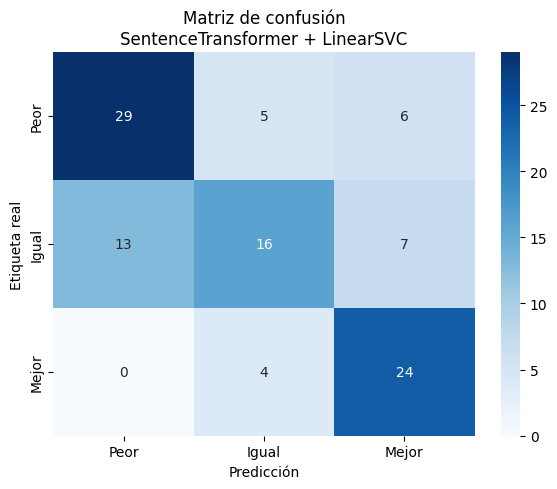

In [ ]:
# EXPLICACIÓN DE LA CELDA
# Calcula y grafica la matriz de confusión del modelo seleccionado.
# La diagonal representa aciertos; las restantes celdas muestran tipos de error.

matriz_confusion = confusion_matrix(
    y_test,
    y_pred_final,
    labels=LABELS
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    matriz_confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=LABELS,
    yticklabels=LABELS
)

plt.title(
    "Matriz de confusión\n"
    f"{MODELO_SELECCIONADO_CV}"
)

plt.xlabel("Predicción")
plt.ylabel("Etiqueta real")
plt.tight_layout()
plt.show()

## Métricas por clase

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Obtiene precision, recall, F1 y soporte por clase a partir de las predicciones finales.

Estas métricas muestran si una clase resulta más difícil, algo que puede quedar oculto en el macro-F1 agregado.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Convierte classification_report en una tabla con métricas por clase.
# Se limita a las tres etiquetas objetivo y conserva su soporte.

reporte_test = classification_report(
    y_test,
    y_pred_final,
    labels=LABELS,
    output_dict=True,
    zero_division=0
)

metricas_por_clase = (
    pd.DataFrame(
        reporte_test
    )
    .T
    .loc[LABELS]
    .reset_index()
    .rename(
        columns={"index": "clase"}
    )
)

display(
    metricas_por_clase.style.format({
        "precision": "{:.3f}",
        "recall": "{:.3f}",
        "f1-score": "{:.3f}",
        "support": "{:.0f}"
    })
)

,clase,precision,recall,f1-score,support
0,Peor,0.690,0.725,0.707,40
1,Igual,0.640,0.444,0.525,36
2,Mejor,0.649,0.857,0.738,28


## Evaluación de palabras direccionales sobre test

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Ajusta la variante enmascarada con todo development y compara ambas versiones sobre test.

Es un análisis complementario de robustez léxica. No se utiliza para volver a elegir el modelo final.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Ajusta la ablación direccional con todo development y la evalúa en test.
# Compara la misma configuración con texto completo y enmascarado.

modelo_direccionales_enmascaradas.fit(
    X_dev_enmascarado,
    y_dev
)

X_test_enmascarado = (
    df_test["texto_original"]
    .apply(
        enmascarar_direccionales
    )
)

pred_test_enmascarado = (
    modelo_direccionales_enmascaradas
    .predict(
        X_test_enmascarado
    )
)

pred_test_tfidf_completo = (
    grid_tfidf_ablation
    .best_estimator_
    .predict(
        df_test["texto_original"]
    )
)

comparacion_direccionales_test = pd.DataFrame([
    {
        "variante": "Texto completo",
        "macro_f1_test": f1_score(
            y_test,
            pred_test_tfidf_completo,
            labels=LABELS,
            average="macro",
            zero_division=0
        )
    },
    {
        "variante": (
            "Palabras direccionales "
            "enmascaradas"
        ),
        "macro_f1_test": f1_score(
            y_test,
            pred_test_enmascarado,
            labels=LABELS,
            average="macro",
            zero_division=0
        )
    }
])

display(
    comparacion_direccionales_test
)

,variante,macro_f1_test
0,Texto completo,0.577649
1,Palabras direccionales enmascaradas,0.527382


## DataFrame para análisis de errores

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Construye una tabla de auditoría con texto original, etiqueta real, predicción, corrección, longitud, negación y presencia de términos direccionales.

Esta tabla distingue los datos originales de las predicciones y sirve como base para el análisis de errores.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Construye el DataFrame de auditoría de predicciones y agrega variables de análisis.
# Las etiquetas reales y las predicciones permanecen en columnas separadas.

analisis_errores = df_test[
    [
        "texto_original",
        "Ventas",
        "grupo",
        "cantidad_palabras",
        "contiene_no"
    ]
].copy()

analisis_errores = (
    analisis_errores
    .rename(
        columns={
            "Ventas": "etiqueta_real"
        }
    )
)

analisis_errores[
    "prediccion"
] = y_pred_final

analisis_errores[
    "correcto"
] = (
    analisis_errores[
        "etiqueta_real"
    ]
    == analisis_errores[
        "prediccion"
    ]
)

analisis_errores[
    "grupo_longitud"
] = np.where(
    analisis_errores[
        "cantidad_palabras"
    ] <= 2,
    "1-2 palabras",
    "3 o más palabras"
)

analisis_errores[
    "contiene_direccional"
] = (
    analisis_errores[
        "texto_original"
    ]
    .apply(
        contiene_direccional
    )
)

display(
    analisis_errores.head()
)

,texto_original,etiqueta_real,grupo,cantidad_palabras,contiene_no,prediccion,correcto,grupo_longitud,contiene_direccional
0,Caída de ingesos de la poblacion,Peor,2,6,False,Peor,True,3 o más palabras,True
1,Mercadería y atención,Mejor,16,3,False,Mejor,True,3 o más palabras,False
2,Distintas opciones de productos naturales,Mejor,21,5,False,Mejor,True,3 o más palabras,False
3,Siempre son los mismos clientes y consumen lo mismo,Igual,29,9,False,Igual,True,3 o más palabras,False
4,La gente no tiene plata para comprar,Peor,34,7,True,Peor,True,3 o más palabras,False


## Resultados por longitud y señales textuales

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Calcula macro-F1 y accuracy en subgrupos definidos por longitud, negación y señales direccionales.

Los tamaños de cada subgrupo deben considerarse al interpretar diferencias: con pocos casos, las métricas son más inestables.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Define una función de evaluación por subgrupo y la aplica a tres señales textuales.
# Cada tabla informa tamaño, macro-F1 y accuracy del subgrupo.

def metricas_por_subgrupo(
    dataframe,
    columna
):
    filas = []

    for valor, grupo in (
        dataframe.groupby(columna)
    ):
        filas.append({
            "subgrupo": valor,
            "cantidad": len(grupo),
            "macro_f1": f1_score(
                grupo["etiqueta_real"],
                grupo["prediccion"],
                labels=LABELS,
                average="macro",
                zero_division=0
            ),
            "accuracy": accuracy_score(
                grupo["etiqueta_real"],
                grupo["prediccion"]
            )
        })

    return pd.DataFrame(filas)


print("Resultados por longitud:")

display(
    metricas_por_subgrupo(
        analisis_errores,
        "grupo_longitud"
    )
)

print("Resultados según presencia de 'no':")

display(
    metricas_por_subgrupo(
        analisis_errores,
        "contiene_no"
    )
)

print("Resultados según palabras direccionales:")

display(
    metricas_por_subgrupo(
        analisis_errores,
        "contiene_direccional"
    )
)

Resultados por longitud:


,subgrupo,cantidad,macro_f1,accuracy
0,1-2 palabras,16,0.566667,0.562500
1,3 o más palabras,88,0.672157,0.681818


Resultados según presencia de 'no':


,subgrupo,cantidad,macro_f1,accuracy
0,False,76,0.671917,0.697368
1,True,28,0.401709,0.571429


Resultados según palabras direccionales:


,subgrupo,cantidad,macro_f1,accuracy
0,False,83,0.649799,0.662651
1,True,21,0.666667,0.666667


## Resumen de confusiones

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Cuenta las combinaciones de etiqueta real y predicción entre los errores.

Permite identificar qué pares de clases se confunden con mayor frecuencia.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Filtra los errores y cuenta cada combinación real-predicha.
# El orden descendente destaca las confusiones más frecuentes.

errores = (
    analisis_errores.loc[
        ~analisis_errores["correcto"]
    ]
    .copy()
)

resumen_confusiones = (
    errores
    .groupby([
        "etiqueta_real",
        "prediccion"
    ])
    .size()
    .reset_index(
        name="cantidad"
    )
    .sort_values(
        "cantidad",
        ascending=False
    )
)

display(
    resumen_confusiones
)

,etiqueta_real,prediccion,cantidad
1,Igual,Peor,13
0,Igual,Mejor,7
4,Peor,Mejor,6
3,Peor,Igual,5
2,Mejor,Igual,4


## Ejemplos concretos de errores

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Muestra hasta cinco ejemplos de cada tipo de confusión con información lingüística auxiliar.

La inspección permite diferenciar posibles errores del modelo, textos ambiguos, respuestas poco informativas y ruido de etiquetado.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Recorre los tipos de confusión y muestra ejemplos concretos de cada uno.
# La muestra se limita a cinco textos para mantener una revisión manejable.

for _, fila in (
    resumen_confusiones.iterrows()
):
    etiqueta_real = fila[
        "etiqueta_real"
    ]

    prediccion = fila[
        "prediccion"
    ]

    print(
        "\n"
        f"Real={etiqueta_real} | "
        f"Predicción={prediccion}"
    )

    display(
        errores.loc[
            (
                errores[
                    "etiqueta_real"
                ]
                == etiqueta_real
            )
            & (
                errores[
                    "prediccion"
                ]
                == prediccion
            ),
            [
                "texto_original",
                "cantidad_palabras",
                "contiene_no",
                "contiene_direccional"
            ]
        ].head(5)
    )


Real=Igual | Predicción=Peor


,texto_original,cantidad_palabras,contiene_no,contiene_direccional
8,La gente no tiene plata,5,True,False
19,El estado de la economía,5,False,False
31,salarios planchados,2,False,False
33,Estamos en época de elecciones y la gente especula,9,False,False
46,"La gente no tiene plata, no suben los sueldos",9,True,True



Real=Igual | Predicción=Mejor


,texto_original,cantidad_palabras,contiene_no,contiene_direccional
7,Clientela desarrollada y producto de calidad,6,False,False
14,Dependiendo ya que los primeros dias del mes es mayor,10,False,False
17,No sé.,2,True,False
41,Tema horario. Tuvieron que aumentar el horario de apertura,9,False,True
81,POCA PLATA,2,False,False



Real=Peor | Predicción=Mejor


,texto_original,cantidad_palabras,contiene_no,contiene_direccional
38,Los precios subieron mucho,4,False,True
65,Aumentaron los precios,3,False,True
73,Suele ser algo de Octubre,5,False,False
83,Por las elecciones y las celebraciones navideñas la gente está ahorrando para gastar en catering en ese momento,18,False,False
84,Y,1,False,False



Real=Peor | Predicción=Igual


,texto_original,cantidad_palabras,contiene_no,contiene_direccional
34,Inflación,1,False,False
47,No hay movimiento,3,True,False
55,Porque la gente no llega a fin de mes.,9,True,False
86,Pode adquisitivo,2,False,False
99,No hay plata en la calle. Esta todo parado.,9,True,False



Real=Mejor | Predicción=Igual


,texto_original,cantidad_palabras,contiene_no,contiene_direccional
23,Buscar precios,2,False,False
30,"Hay un colegio en frente, no les afecta mucho la inflación.",11,True,False
69,porque se asentaron los precios,5,False,False
72,Por la estabilidad de los precios de proveedores,8,False,False


## Features asociadas con cada clase

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Recupera los coeficientes más positivos del mejor modelo lineal de palabras para cada clase.

Los coeficientes indican asociaciones predictivas dentro de ese modelo; no explican directamente el SentenceTransformer ni implican causalidad.


Para interpretar asociaciones utilizamos el mejor modelo lineal de palabras, aunque no sea el modelo ganador general.

<!-- EXPLICACION_AGREGADA -->
El modelo lineal se usa como herramienta de interpretación porque sus features y coeficientes son observables. El modelo contextual ganador representa oraciones completas y no ofrece los mismos coeficientes léxicos.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Extrae las features con coeficientes positivos más altos del mejor modelo lineal.
# La salida facilita interpretación léxica, pero no representa causalidad.

mejor_pipeline_palabras = (
    grid_mejor_palabras
    .best_estimator_
)

vectorizador_palabras = (
    mejor_pipeline_palabras
    .named_steps[
        "vectorizador"
    ]
)

clasificador_palabras = (
    mejor_pipeline_palabras
    .named_steps[
        "clasificador"
    ]
)

features = (
    vectorizador_palabras
    .get_feature_names_out()
)

filas_features = []

for indice_clase, clase in enumerate(
    clasificador_palabras.classes_
):
    coeficientes = (
        clasificador_palabras
        .coef_[indice_clase]
    )

    indices_top = np.argsort(
        coeficientes
    )[-15:][::-1]

    for posicion, indice_feature in enumerate(
        indices_top,
        start=1
    ):
        filas_features.append({
            "clase": clase,
            "posicion": posicion,
            "feature": (
                features[
                    indice_feature
                ]
            ),
            "coeficiente": (
                coeficientes[
                    indice_feature
                ]
            )
        })


top_features = pd.DataFrame(
    filas_features
)

display(
    top_features.pivot(
        index="posicion",
        columns="clase",
        values="feature"
    )
)

clase,Igual,Mejor,Peor
posicion,,,
1,mism,mas,gobiern
2,clientel,tempor,situacion
3,mantien,mejor,polit
4,se mantien,buen,plat
5,economi,estacional,la situacion
6,hay,clim,competent
7,no hay,respond,pais
8,el context,no respond,baj
9,ningun,conoc,especul


## Guardado de resultados

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Exporta tablas de resultados y análisis en archivos CSV dentro de `/content`.

Los archivos permiten reproducir tablas del informe sin volver a ejecutar los modelos. La notebook sigue siendo la fuente de la metodología y del orden de ejecución.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Exporta las tablas principales a CSV dentro del entorno de Colab.
# No vuelve a calcular métricas: guarda los objetos ya construidos.

tabla_palabras.to_csv(
    "/content/resultados_modelos_palabras_cv.csv",
    index=False
)

resultados_familias_cv.to_csv(
    "/content/resultados_familias_cv.csv",
    index=False
)

resultados_test.to_csv(
    "/content/resultados_test.csv",
    index=False
)

metricas_por_clase.to_csv(
    "/content/metricas_por_clase_test.csv",
    index=False
)

comparacion_direccionales_cv.to_csv(
    "/content/comparacion_direccionales_cv.csv",
    index=False
)

comparacion_direccionales_test.to_csv(
    "/content/comparacion_direccionales_test.csv",
    index=False
)

analisis_errores.to_csv(
    "/content/analisis_errores_test.csv",
    index=False
)

top_features.to_csv(
    "/content/features_por_clase.csv",
    index=False
)

print("Resultados guardados correctamente.")

Resultados guardados correctamente.


## Resumen automático para las conclusiones

<!-- EXPLICACION_AGREGADA -->
**Qué hace.** Imprime una síntesis automática del modelo seleccionado, su desempeño, intervalo bootstrap y experimento direccional.

**Corrección documentada.** Se reconstruye `intervalo_confianza` desde la tabla bootstrap del modelo seleccionado para que esta celda funcione también en una sesión limpia. Este ajuste no modifica ninguna métrica ni resultado.


In [ ]:
# EXPLICACIÓN DE LA CELDA
# Imprime una síntesis final a partir de objetos calculados en celdas anteriores.
# Distingue el modelo seleccionado por CV del mayor valor puntual observado en test.

mejor_fila_test = (
    resultados_test.iloc[0]
)

print("RESUMEN DE RESULTADOS")
print("-" * 60)

print(
    "Modelo seleccionado por validación cruzada:",
    MODELO_SELECCIONADO_CV
)

print(
    "Modelo con mayor macro-F1 observado en test:",
    mejor_fila_test["modelo"]
)

print(
    "Macro-F1 del modelo seleccionado:",
    round(
        f1_score(
            y_test,
            y_pred_final,
            labels=LABELS,
            average="macro",
            zero_division=0
        ),
        3
    )
)

print(
    "Accuracy del modelo seleccionado:",
    round(
        accuracy_score(
            y_test,
            y_pred_final
        ),
        3
    )
)

print(
    "Intervalo bootstrap 95%:",
    round(
        intervalo_confianza[
            "limite_inferior_95"
        ],
        3
    ),
    "-",
    round(
        intervalo_confianza[
            "limite_superior_95"
        ],
        3
    )
)

print(
    "Macro-F1 con texto completo:",
    round(
        comparacion_direccionales_test
        .loc[
            comparacion_direccionales_test[
                "variante"
            ]
            == "Texto completo",
            "macro_f1_test"
        ]
        .iloc[0],
        3
    )
)

print(
    "Macro-F1 con palabras direccionales enmascaradas:",
    round(
        comparacion_direccionales_test
        .loc[
            comparacion_direccionales_test[
                "variante"
            ]
            == (
                "Palabras direccionales "
                "enmascaradas"
            ),
            "macro_f1_test"
        ]
        .iloc[0],
        3
    )
)

RESUMEN DE RESULTADOS
------------------------------------------------------------
Modelo seleccionado por validación cruzada: SentenceTransformer + LinearSVC
Modelo con mayor macro-F1 observado en test: SentenceTransformer + LinearSVC
Macro-F1 del modelo seleccionado: 0.657
Accuracy del modelo seleccionado: 0.663
Intervalo bootstrap 95%: 0.571 - 0.74
Macro-F1 con texto completo: 0.578
Macro-F1 con palabras direccionales enmascaradas: 0.527
